# 03 — Las fuentes externas: de dónde sale cada dato

## Qué contesta este cuaderno

Es el inventario de `calendarios/docs/INVENTARIO.md` en forma de cuaderno. Para cada familia de
variables externas dice:
- qué es y qué **entidad** la publica, con su dirección;
- cómo se descarga o se rehace;
- con cuánto **rezago** se publica;
- qué **cobertura** tiene frente al triage;
- y cómo se comporta su serie, **con sus escalones**.

**Aquí no se correlaciona nada con el triage.** Eso lo hacen el 06 y el 07. Aquí se describe la
materia prima: qué puede sostener cada fuente y qué no. La regla del proyecto es mirar la serie
de una columna antes de usarla, porque un cambio de registro se parece mucho a un efecto.

Orden:
1. Cobertura temporal de todas las fuentes.
2. Salud pública (SIVIGILA y Power BI del INS).
3. Clima.
4. Seguridad (MinDefensa).
5. La red de salud (entidad administradora del triage).
6. Calendario, eventos y desastres.
7. Calidad: los escalones conocidos, en una tabla.
8. Lo que no existe como dato.

## De dónde salen los datos

El cuaderno no se conecta a ninguna base: lee archivos agregados del repositorio. Ninguno trae una
columna de persona. Las URL y el detalle de cada fuente están en `calendarios/docs/`
(`VIGILANCIA.md`, `FUENTES_VIGILANCIA.md`, `FUENTES_EXTERNAS.md`, `CLIMA.md`).

| Familia | Archivo | Quién lo publica | Origen | Cómo se rehace | Rezago |
|---|---|---|---|---|---|
| Triage (desenlace) | `salidas/triage_diario.parquet` | SES Hospital Universitario de Caldas | base del hospital, `DIM_TRIAGE`, agregada por día | solo el propietario (`python -m extraccion`) | al día de la extracción |
| Red de salud | `salidas/triage_entidad.parquet` | SES Hospital Universitario de Caldas | `DIM_TRIAGE.GEENENTADM` → `DIM_ENTIDAD`, día × hora × entidad | solo el propietario (`python -m extraccion --entidad`); grupos con `python -m extraccion.entidades` | al día de la extracción |
| Vigilancia 995 y 998 | `calendarios/vigilancia_sivigila.csv.gz`, `…_instituciones.csv.gz` | Instituto Nacional de Salud (INS) | microdatos SIVIGILA, `https://portalsivigila.ins.gov.co/Microdatos/Datos_{AÑO}_{EVENTO}.xlsx` | `python calendarios/vigilancia/sivigila.py --eventos 995 998 --desde 2011` | ~8 meses |
| Vigilancia, eventos individuales | `calendarios/vigilancia_sivigila_eventos.csv.gz`, `…_eventos_censo.csv` | INS | los mismos microdatos | `python calendarios/vigilancia/eventos.py --sin-red` (con `--descargar` baja el crudo) | ~8 meses |
| Vigilancia 2026 | `calendarios/vigilancia/powerbi/AAAA-MM-DD/` | INS | tablero Power BI «006 Vigilancia Rutinaria» y tableros por evento; la clave se lee de la lista `MenuReporteNivel2` de `portalsivigila.ins.gov.co` | `python calendarios/vigilancia/powerbi.py` (congela la descarga del día) | ~7 días |
| Clima | `calendarios/clima_unificado.csv.gz` | IDEAM; Aerocivil (METAR de La Nubia) vía Iowa Environmental Mesonet; Open-Meteo (ERA5); NASA POWER | ver sección 3 | `python calendarios/clima/clima_manizales.py` y `python calendarios/clima/clima_unificado.py` | días |
| Seguridad | `calendarios/seguridad_mindefensa.csv.gz` | Ministerio de Defensa Nacional (Policía) | `https://www.datos.gov.co/resource/<id>.json` | `python calendarios/seguridad/mindefensa.py` | 2-6 semanas |
| Calendario | `calendarios/calendario_Colombia.csv` | festivos de ley (librería `holidays`) y reglas propias | — | `python calendarios/calendario_colombia.py --inicio 2020-01-01 --fin 2026-12-31` | se conoce de antemano |
| Eventos, desastres, vigilancia manual | `calendarios/eventos_…csv`, `desastres_…csv`, `vigilancia_salud_…csv` | escritos a mano; cada fila con su `fuente_url` | prensa, Alcaldía, INS, IDEAM… | a mano | — |

**Privacidad.** Los Excel del SIVIGILA traen nombre, teléfono y correo de quien notifica; se
descartan en el mismo paso de lectura y el crudo está ignorado por git. De los tableros de Power BI
solo se piden medidas agregadas. De MinDefensa, solo sumas por día. El archivo por entidad trae
nombres de aseguradoras, no de personas, y aquí solo se muestran los grupos.

In [1]:
import sys, pathlib, warnings, json
from urllib.parse import urlparse
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "legend.frameon": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

CAL = RAIZ / "calendarios"
PBI = sorted(p for p in (CAL / "vigilancia" / "powerbi").glob("20*") if p.is_dir())[-1]   # ultima instantanea

tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
ent = clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
vig = pd.read_csv(CAL / "vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
eve = pd.read_csv(CAL / "vigilancia_sivigila_eventos.csv.gz", parse_dates=["fecha_inicio_semana"])
censo = pd.read_csv(CAL / "vigilancia_sivigila_eventos_censo.csv")
inst = pd.read_csv(CAL / "vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
clima = pd.read_csv(CAL / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
seg = pd.read_csv(CAL / "seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha")
calc = pd.read_csv(CAL / "calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
eventos = pd.read_csv(CAL / "eventos_manizales_2020_2026.csv")
desastres = pd.read_csv(CAL / "desastres_manizales_2020_2026.csv")
vman = pd.read_csv(CAL / "vigilancia_salud_manizales_caldas.csv")
pbi = {p.stem: pd.read_csv(p) for p in PBI.glob("*.csv")}
meta = json.load(open(PBI / "metadatos.json", encoding="utf-8"))
SES = 170010010301

def inicio_semana_epi(anio, semana):
    """Domingo que abre la semana epidemiologica: la SE1 es la que contiene el 4 de enero."""
    d = pd.Timestamp(anio, 1, 4)
    return d - pd.Timedelta(days=(d.dayofweek + 1) % 7) + pd.Timedelta(weeks=int(semana) - 1)

def tramos(mascara):
    """Tramos contiguos de dias en True, como (inicio, duracion) para broken_barh."""
    m = mascara.astype(bool)
    grupo = (m != m.shift()).cumsum()
    return [(mdates.date2num(g.index[0]), len(g)) for _, g in m.groupby(grupo) if g.iloc[0]]

print(f"triage diario: {tri.dia.min():%Y-%m-%d} a {tri.dia.max():%Y-%m-%d}; "
      f"por entidad: {ent.dia.min():%Y-%m-%d} a {ent.dia.max():%Y-%m-%d}")
print(f"instantanea Power BI: {PBI.name} (descargada {meta['descargado']}; refresco del INS del 006: "
      f"{meta['archivos']['rutinaria_manizales.csv']['refresco_ins']})")

triage diario: 2020-01-01 a 2026-09-21; por entidad: 2020-01-01 a 2026-09-28
instantanea Power BI: 2026-09-28 (descargada 2026-09-28T11:30:08; refresco del INS del 006: 2026-09-26T22:04:29.627)


---
# 1. Cobertura temporal: qué hay y cuándo

Una barra por fuente, de 2011 a 2026. La franja gris es el periodo en que existe el triage. Las
filas «días con pluviómetro» y «días con METAR» son las medidas **en tierra** que hay debajo del
clima unificado: el consenso cubre todos los días, pero no todos los días tienen una medida real.

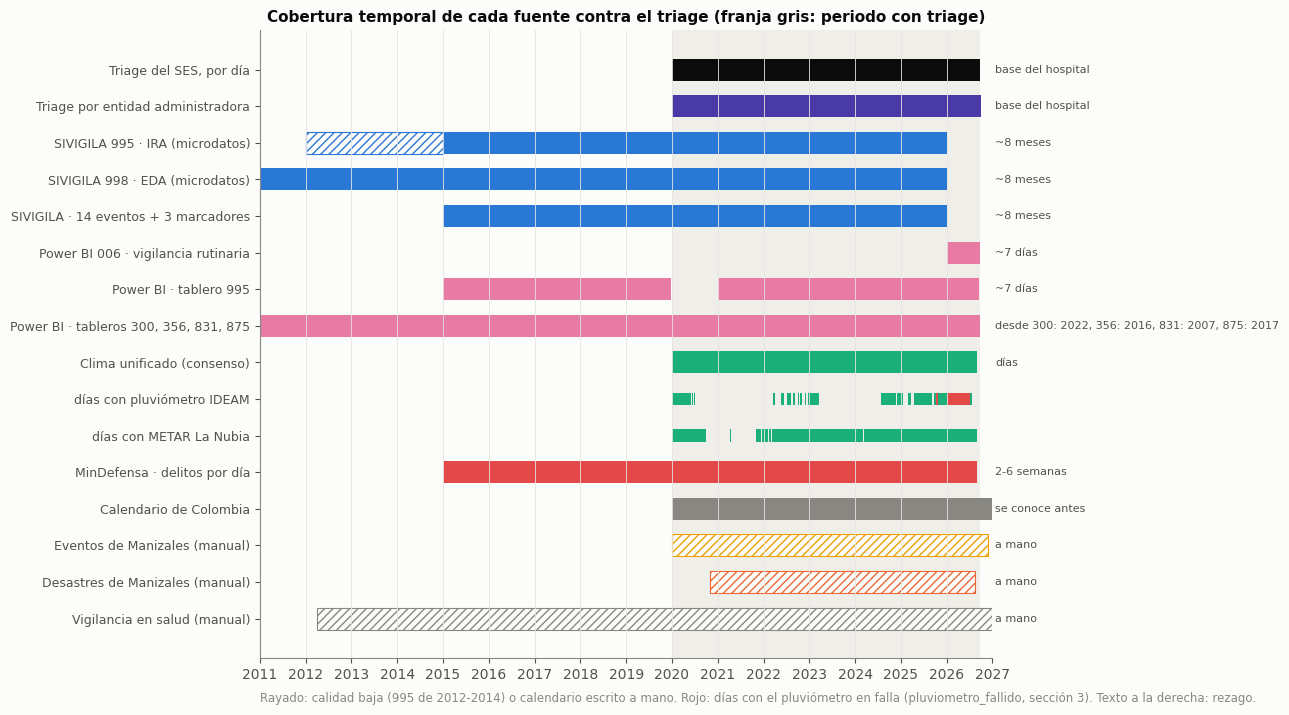

días con el pluviómetro en falla (pluviometro_fallido): 199, del 2025-10-05 al 2026-07-08; meses: ['2025-10', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07']


,desde,hasta
fuente,,
"Triage del SES, por día",2020-01-01,2026-09-21
Triage por entidad administradora,2020-01-01,2026-09-28
SIVIGILA 995 · IRA (microdatos),2012-01-01,2026-01-03
SIVIGILA 998 · EDA (microdatos),2011-01-02,2026-01-03
SIVIGILA · 14 eventos + 3 marcadores,2015-01-04,2026-01-03
Power BI 006 · vigilancia rutinaria,2026-01-04,2026-09-26
Power BI · tablero 995,2015-01-04,2026-09-19
"Power BI · tableros 300, 356, 831, 875",2007-01-01,2026-09-26
Clima unificado (consenso),2020-01-01,2026-08-28


In [2]:
AN = lambda a, b=None: (pd.Timestamp(a), pd.Timestamp(b) if b else pd.Timestamp(a))
dias_clima = clima.index
filas = []   # (familia, etiqueta, color, [(ini, fin, estilo)], nota)
filas.append(("desenlace", "Triage del SES, por día", TINTA, [(tri.dia.min(), tri.dia.max(), "ok")], "base del hospital"))
filas.append(("red", "Triage por entidad administradora", VIOLETA, [(ent.dia.min(), ent.dia.max(), "ok")], "base del hospital"))

m995 = vig[(vig.ambito == "manizales") & (vig.evento == 995)]
m998 = vig[(vig.ambito == "manizales") & (vig.evento == 998)]
f995 = m995.groupby("anio").fecha_inicio_semana.agg(["min", "max"])
f998 = m998.groupby("anio").fecha_inicio_semana.agg(["min", "max"])
filas.append(("salud", "SIVIGILA 995 · IRA (microdatos)", AZUL,
              [(f995.loc[2012, "min"], f995.loc[2014, "max"] + pd.Timedelta(days=6), "baja"),
               (f995.loc[2015, "min"], f995.loc[2025, "max"] + pd.Timedelta(days=6), "ok")], "~8 meses"))
filas.append(("salud", "SIVIGILA 998 · EDA (microdatos)", AZUL,
              [(f998["min"].min(), f998["max"].max() + pd.Timedelta(days=6), "ok")], "~8 meses"))
fe = eve[eve.ambito == "manizales"].fecha_inicio_semana
filas.append(("salud", "SIVIGILA · 14 eventos + 3 marcadores", AZUL, [(fe.min(), fe.max() + pd.Timedelta(days=6), "ok")], "~8 meses"))
rut = pbi["rutinaria_manizales"]
filas.append(("salud", "Power BI 006 · vigilancia rutinaria", MAGENTA,
              [(inicio_semana_epi(2026, 1), inicio_semana_epi(2026, rut.semana.max()) + pd.Timedelta(days=6), "ok")], "~7 días"))
tb = pbi["ira_995_tablero"]; anios_tb = sorted(tb.anio.unique())
seg_tb, ini_ = [], anios_tb[0]
for a, b in zip(anios_tb, anios_tb[1:] + [None]):
    if b != a + 1:
        fin_ = inicio_semana_epi(a, tb[tb.anio == a].semana.max()) + pd.Timedelta(days=6)
        seg_tb.append((inicio_semana_epi(ini_, 1), fin_, "ok")); ini_ = b
filas.append(("salud", "Power BI · tablero 995", MAGENTA, seg_tb, "~7 días"))
inicio_ev = {k.split("_")[1]: int(v[v.casos > 0].anio.min()) for k, v in pbi.items() if k.startswith("evento_")}
filas.append(("salud", "Power BI · tableros 300, 356, 831, 875", MAGENTA,
              [(pd.Timestamp(min(inicio_ev.values()), 1, 1), pd.Timestamp("2026-09-26"), "ok")],
              "desde " + ", ".join(f"{k}: {v}" for k, v in sorted(inicio_ev.items()))))
filas.append(("clima", "Clima unificado (consenso)", AQUA, [(dias_clima.min(), dias_clima.max(), "ok")], "días"))
filas.append(("clima", "  días con pluviómetro IDEAM", AQUA, tramos(clima.precip_con_estacion.astype(bool)), "tramos"))
# Dias con el pluviometro en falla: los marca clima_unificado.py desde el 2026-09-29 (columna
# pluviometro_fallido) y ya no cuentan como dias con pluviometro. Antes de esa fecha este cuaderno
# los detectaba por su cuenta, por meses; ahora solo los lee.
FALLA = clima.pluviometro_fallido.astype(bool)
MESES_FALLA = [m.to_timestamp() for m in FALLA.groupby(clima.index.to_period("M")).sum()[lambda s: s > 0].index]
filas.append(("clima", "  días con METAR La Nubia", AQUA, tramos(clima.iem_tmedia_c.notna()), "tramos"))
filas.append(("seguridad", "MinDefensa · delitos por día", ROJO, [(seg.index.min(), seg.index.max(), "ok")], "2-6 semanas"))
filas.append(("calendario", "Calendario de Colombia", MUDO, [(calc.index.min(), calc.index.max(), "ok")], "se conoce antes"))
filas.append(("manual", "Eventos de Manizales (manual)", AMARILLO,
              [(pd.to_datetime(eventos.fecha_inicio).min(), pd.to_datetime(eventos.fecha_fin).max(), "manual")], "a mano"))
filas.append(("manual", "Desastres de Manizales (manual)", NARANJA,
              [(pd.to_datetime(desastres.fecha_inicio).min(), pd.to_datetime(desastres.fecha_fin).max(), "manual")], "a mano"))
filas.append(("manual", "Vigilancia en salud (manual)", MUDO,
              [(pd.to_datetime(vman.fecha_inicio).min(), pd.to_datetime(vman.fecha_fin).max(), "manual")], "a mano"))

fig, ax = plt.subplots(figsize=(13, 7.2))
ax.axvspan(mdates.date2num(tri.dia.min()), mdates.date2num(tri.dia.max()), color="#efeee9", zorder=0, lw=0)
X0, X1 = mdates.date2num(pd.Timestamp("2011-01-01")), mdates.date2num(pd.Timestamp("2027-01-01"))
for i, (fam, etq, col, segs, nota) in enumerate(filas):
    y = len(filas) - i
    alto = 0.34 if etq.startswith("  ") else 0.6
    for s in segs:
        if nota == "tramos":
            ax.broken_barh([s], (y - alto / 2, alto), color=col, lw=0)
            continue
        ini, fin, est = s
        a, b = max(mdates.date2num(ini), X0), mdates.date2num(fin)
        estilo = dict(color=col, lw=0) if est == "ok" else dict(facecolor=SUP, edgecolor=col, hatch="////", lw=.8)
        ax.broken_barh([(a, b - a)], (y - alto / 2, alto), **estilo)
    if etq.strip() == "días con pluviómetro IDEAM":
        ax.broken_barh(tramos(FALLA), (y - alto / 2, alto), color=ROJO, lw=0)
    if nota != "tramos":
        ax.text(X1 + 20, y, nota, va="center", fontsize=8, color=TINTA2)
ax.set_yticks([len(filas) - i for i in range(len(filas))], [f[1] for f in filas], fontsize=9)
ax.set_xlim(X0, X1); ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator(1)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title("Cobertura temporal de cada fuente contra el triage (franja gris: periodo con triage)")
ax.text(0, -.07, "Rayado: calidad baja (995 de 2012-2014) o calendario escrito a mano. Rojo: días con el pluviómetro en falla (pluviometro_fallido, sección 3). Texto a la derecha: rezago.",
        transform=ax.transAxes, fontsize=8.5, color=MUDO)
plt.tight_layout(); plt.show()

tabla = pd.DataFrame([{"fuente": f[1].strip(), "desde": min(s[0] for s in f[3]) if f[4] != "tramos" else mdates.num2date(f[3][0][0]).date(),
                       "hasta": max(s[1] for s in f[3]) if f[4] != "tramos" else mdates.num2date(f[3][-1][0] + f[3][-1][1] - 1).date()}
                      for f in filas])
tabla["desde"] = pd.to_datetime(tabla.desde).dt.date; tabla["hasta"] = pd.to_datetime(tabla.hasta).dt.date
print(f"días con el pluviómetro en falla (pluviometro_fallido): {FALLA.sum()}, del {FALLA[FALLA].index.min():%Y-%m-%d} "
      f"al {FALLA[FALLA].index.max():%Y-%m-%d}; meses: {[f'{m:%Y-%m}' for m in MESES_FALLA]}")
tabla.set_index("fuente")

## Lectura

**Todo lo que se necesita cubre el periodo del triage, pero con tres salvedades.**

- **Lo que cubre el triage entero** (2020-01-01 a 2026-09-21): clima (hasta el 2026-08-28),
  MinDefensa (hasta el 2026-08-31), calendario y entidad administradora (hasta el 2026-09-28).
- **Los microdatos del SIVIGILA terminan en la SE53 de 2025** (2026-01-03). 2026 solo existe por
  Power BI: **una sola instantánea**, la del 2026-09-28, con 38 semanas en el 006.
- **El tablero 995 de Power BI no tiene 2020.** Tiene 2015-2019 y 2021-2026.
- **El clima tiene menos medida real de lo que parece.** El pluviómetro IDEAM falta de agosto de
  2020 a diciembre de 2021 y de abril de 2023 a junio de 2024. El METAR casi no tiene datos de octubre de
  2020 a octubre de 2021. **En rojo, los meses en que el pluviómetro reporta casi cero**: 2025-10 y de
  2026-01 a 2026-06 (sección 3). Es un problema nuevo.
- Los tres calendarios manuales cubren 2020-2026, pero son **listas de fechas**, no series.

**Límite.** Una barra dice que hay archivo, no que el dato sea bueno. Para eso están las secciones
siguientes.

> **Corrección del 2026-09-29 (clima corregido).** El rojo ya no lo calcula este cuaderno: lo marca
> `clima_unificado.py` en la columna nueva `pluviometro_fallido`, y esos días **dejan de contar como
> días con pluviómetro**. Antes → después:
> - qué se pinta: meses enteros con ≥ 15 días de lectura y menos del 10 % de NASA, detectados aquí
>   (2025-10 y 2026-01 a 2026-06) → **199 días** marcados por el script, del **2025-10-05 al
>   2026-07-08** (20 de octubre de 2025, 25 de enero, todo febrero a junio y 5 de julio de 2026);
> - en la barra aguamarina, esos días eran «con pluviómetro» → ahora son hueco, y el consenso los llena
>   con NASA escalado. El criterio está en la sección 3.

---
# 2. Salud pública: el SIVIGILA del INS

## 2.1 Evento 995: consultas por IRA con su denominador

**Qué es.** Notificación **colectiva semanal** de cada institución (UPGD): consultas por IRA y por
todas las causas, hospitalizaciones, UCI y muertes, en 7 grupos de edad. Sale de los RIPS. Es la
única fuente de vigilancia con **denominador**.

- **Publica:** Instituto Nacional de Salud, `https://portalsivigila.ins.gov.co/Microdatos/Datos_{AÑO}_995.xlsx`.
- **Se rehace con** `python calendarios/vigilancia/sivigila.py --eventos 995 998 --desde 2011`
  (`--sin-descargar` lo rehace desde el caché, ~16 s).
- **Rezago: ~8 meses.** 2025 salió el 25 de agosto de 2026. Sirve para entrenar y medir, no para
  operar.
- Porqué de la construcción: `calendarios/docs/VIGILANCIA.md`.

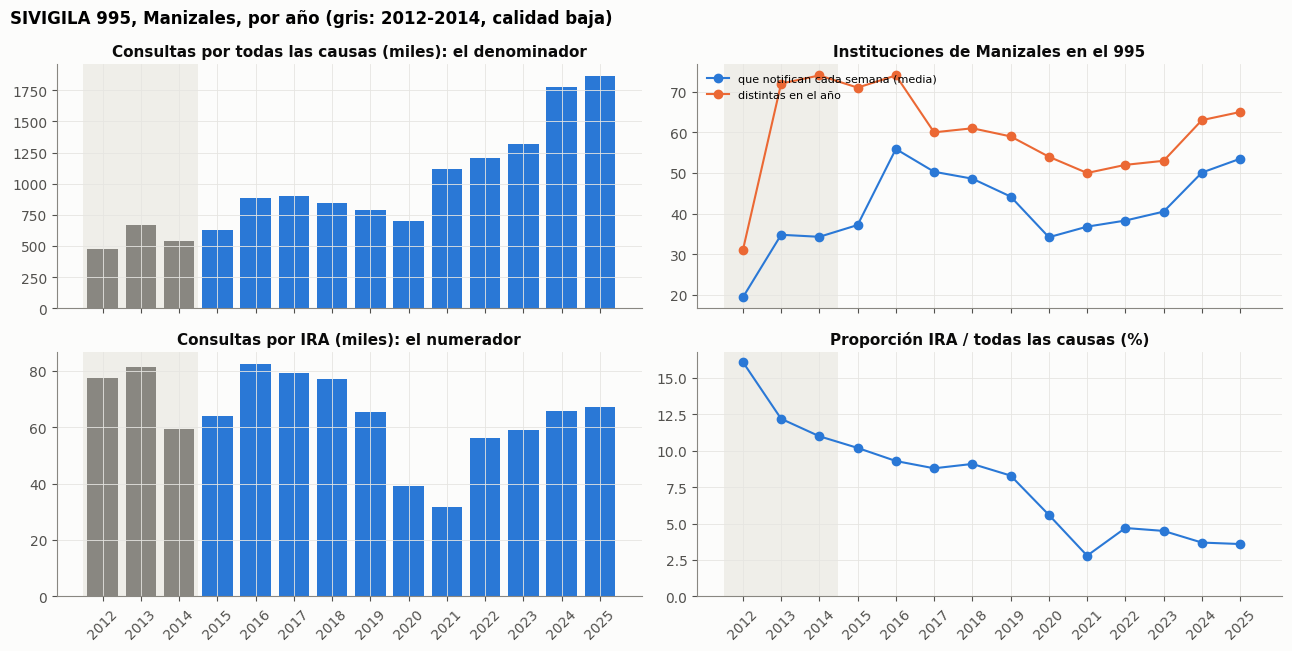

,consultas todas las causas,consultas IRA,% IRA,instituciones por semana,instituciones distintas,nuevas respecto del año anterior,% del denominador que es el SES
2012,479549.0,77435.0,16.1,19.4,31,NaN,13.3
2013,668816.0,81330.0,12.2,34.8,72,45.0,11.9
2014,542856.0,59487.0,11.0,34.3,74,13.0,11.1
2015,627569.0,64048.0,10.2,37.2,71,10.0,9.4
2016,886471.0,82486.0,9.3,55.9,74,15.0,6.8
2017,902920.0,79259.0,8.8,50.3,60,2.0,7.2
2018,848803.0,77002.0,9.1,48.6,61,5.0,6.3
2019,786067.0,65291.0,8.3,44.2,59,3.0,9.5
2020,700847.0,39261.0,5.6,34.2,54,1.0,7.1
2021,1121559.0,31648.0,2.8,36.8,50,0.0,6.1


In [3]:
todas = m995[m995.variable == "consultas_todas_causas_total"].groupby("anio").valor.sum()
ira = m995[m995.variable == "consultas_ira_total"].groupby("anio").valor.sum()
n_inst = m995[m995.variable == "n_instituciones_notificando"].groupby("anio").valor.mean()
i995 = inst[inst.evento == 995]
distintas = i995.groupby("anio").cod_upgd.nunique()
conj = i995.groupby("anio").cod_upgd.apply(set)
nuevas = pd.Series({a: len(conj[a] - conj[a - 1]) if a - 1 in conj.index else np.nan for a in conj.index})
ses = i995[i995.cod_upgd == SES].groupby("anio").consultas_todas_causas.sum()
A995 = pd.DataFrame({"consultas todas las causas": todas, "consultas IRA": ira, "% IRA": 100 * ira / todas,
                     "instituciones por semana": n_inst, "instituciones distintas": distintas,
                     "nuevas respecto del año anterior": nuevas, "% del denominador que es el SES": 100 * ses.reindex(todas.index).fillna(0) / todas}).round(1)

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True)
col = [MUDO if a < 2015 else AZUL for a in A995.index]
axes[0, 0].bar(A995.index, A995["consultas todas las causas"] / 1e3, color=col); axes[0, 0].set_title("Consultas por todas las causas (miles): el denominador")
axes[0, 1].plot(A995.index, A995["instituciones por semana"], "o-", color=AZUL, label="que notifican cada semana (media)")
axes[0, 1].plot(A995.index, A995["instituciones distintas"], "o-", color=NARANJA, label="distintas en el año")
axes[0, 1].set_title("Instituciones de Manizales en el 995"); axes[0, 1].legend(fontsize=8, loc="upper left")
axes[1, 0].bar(A995.index, A995["consultas IRA"] / 1e3, color=col); axes[1, 0].set_title("Consultas por IRA (miles): el numerador")
axes[1, 1].plot(A995.index, A995["% IRA"], "o-", color=AZUL); axes[1, 1].set_title("Proporción IRA / todas las causas (%)")
axes[1, 1].set_ylim(0, None)
for ax in axes.flat:
    ax.axvspan(2011.5, 2014.5, color="#efeee9", zorder=0, lw=0)
axes[1, 0].set_xticks(A995.index, A995.index, rotation=45)
axes[1, 1].set_xticks(A995.index, A995.index, rotation=45)
fig.suptitle("SIVIGILA 995, Manizales, por año (gris: 2012-2014, calidad baja)", fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
A995

## Lectura

**El numerador es estable; el denominador no.**

| | 2015 | 2020 | 2021 | 2023 | 2024 | 2025 |
|---|---|---|---|---|---|---|
| Consultas por todas las causas | 627.569 | 700.847 | **1.121.559** | 1.318.518 | **1.773.774** | 1.864.363 |
| Consultas por IRA | 64.048 | 39.261 | 31.648 | 58.878 | 65.791 | 67.220 |
| % IRA | 10,2 | 5,6 | 2,8 | 4,5 | 3,7 | 3,6 |

- **El denominador casi se triplica** entre 2015 y 2025, en dos saltos: **+60 %** de 2020 a 2021 y
  **+35 %** de 2023 a 2024. En 2024 hay 11 instituciones nuevas respecto de 2023, y las que
  notifican cada semana pasan de 40,5 a 50,1.
- **La IRA se mueve entre ~56.000 y ~82.000 consultas al año** fuera de la pandemia.
- Por eso **la caída de la proporción, del 10,2 % al 3,6 %, es del denominador**, no de la IRA.
- **2012-2014 no son comparables**: 2013 tiene 72 instituciones distintas contra 31 en 2012 (45
  nuevas). Duplicados y semanas con 2 instituciones (`VIGILANCIA.md`).
- **El SES pesa entre el 6 y el 10 % del denominador** de la ciudad desde 2015. Por eso se excluye
  cuando «consultas de la ciudad» se usa como variable externa (cuaderno 06).

**Qué puede sostener.** El **conteo** de IRA entre años y la **proporción dentro de un mismo año**.

**Qué no.**
- La proporción entre años, sin un panel fijo de instituciones (pendiente).
- «Demanda urgente»: el total mezcla consulta externa programada con urgencias.

## 2.2 Evento 998: enfermedad diarreica aguda (EDA)

**Qué es.** Casos de EDA, notificación colectiva, en 18 grupos de edad. **No trae denominador**: la
proporción se calcula contra el del 995. Misma fuente, mismo comando y mismo rezago que el 995. En
2011, 2012 y 2014 el archivo es una tabla municipal sin institución, por eso esos años no tienen
número de instituciones.

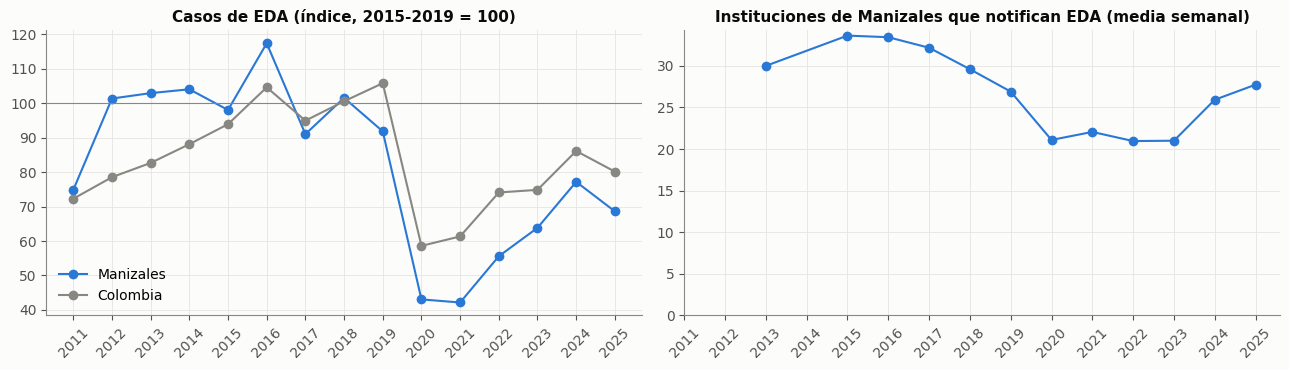

,casos Manizales,índice Manizales,índice Colombia,instituciones por semana
anio,,,,
2011,23337.0,75.0,72.0,NaN
2012,31606.0,101.0,79.0,NaN
2013,32094.0,103.0,83.0,30.0
2014,32442.0,104.0,88.0,NaN
2015,30569.0,98.0,94.0,33.6
2016,36606.0,117.0,105.0,33.4
2017,28382.0,91.0,95.0,32.2
2018,31666.0,102.0,101.0,29.6
2019,28632.0,92.0,106.0,26.9


In [4]:
eda = m998[m998.variable == "casos_eda_total"].groupby("anio").valor.sum()
eda_col = vig[(vig.ambito == "colombia") & (vig.evento == 998) & (vig.variable == "casos_eda_total")].groupby("anio").valor.sum()
n998 = m998[m998.variable == "n_instituciones_notificando"].groupby("anio").valor.mean()
base = lambda s: 100 * s / s.loc[2015:2019].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(eda.index, base(eda), "o-", color=AZUL, label="Manizales")
axes[0].plot(eda_col.index, base(eda_col), "o-", color=MUDO, label="Colombia")
axes[0].axhline(100, color=MUDO, lw=.8); axes[0].set_title("Casos de EDA (índice, 2015-2019 = 100)"); axes[0].legend(loc="lower left")
axes[1].plot(n998.index, n998, "o-", color=AZUL); axes[1].set_title("Instituciones de Manizales que notifican EDA (media semanal)")
axes[1].set_ylim(0, None)
for ax in axes: ax.set_xticks(range(2011, 2026), range(2011, 2026), rotation=45)
plt.tight_layout(); plt.show()
pd.DataFrame({"casos Manizales": eda, "índice Manizales": base(eda).round(0), "índice Colombia": base(eda_col).round(0),
              "instituciones por semana": n998.round(1)})

## Lectura

**La EDA de Manizales cae a menos de la mitad en 2020 y no se ha recuperado del todo.**

| | 2015-2019 | 2020 | 2021 | 2024 | 2025 |
|---|---|---|---|---|---|
| Índice Manizales | 91-117 | **43** | **42** | 77 | 69 |
| Índice Colombia | 94-106 | 59 | 61 | 86 | 80 |
| Instituciones por semana | 26,9-33,6 | 21,1 | 22,1 | 25,9 | 27,7 |

- **Manizales cae más que el país** y se recupera menos.
- **Las instituciones que notifican también caen**, de 33,6 por semana en 2015 a ~21 entre 2020 y
  2023. Parte de la caída puede ser de notificación y parte real. **Con estos datos no se separa.**

**Límite.** Las instituciones del 998 no son las del 995: en 2025, 27,7 por semana contra 53,5. La
proporción EDA / consultas del 995 es una aproximación.

## 2.3 Eventos individuales: una fila por caso

**Qué es.** Las fichas de notificación individual del SIVIGILA. Se cuentan los casos de Manizales
por **municipio de ocurrencia**, por semana epidemiológica.

- **Publica:** INS, los mismos microdatos.
- **Se rehace con** `python calendarios/vigilancia/eventos.py --sin-red` (series desde el crudo;
  `--descargar --seleccionados` baja 2007-2025 de lo elegido).
- **Rezago:** ~8 meses.
- **Selección, fijada por el propietario:** entra como serie el evento con **al menos 1 caso por
  semana en 2023-2025**. Son 14 series y 3 marcadores. Al leer se aplica una lista blanca: edad,
  sexo, documento y aseguradora no se leen nunca.

La figura muestra los casos por año de cada uno. **Aviso de fuga:** 300, 875, 356, 365 y 549 son
personas que consultan en urgencias, parte del propio desenlace. Solo pueden entrar con rezago.

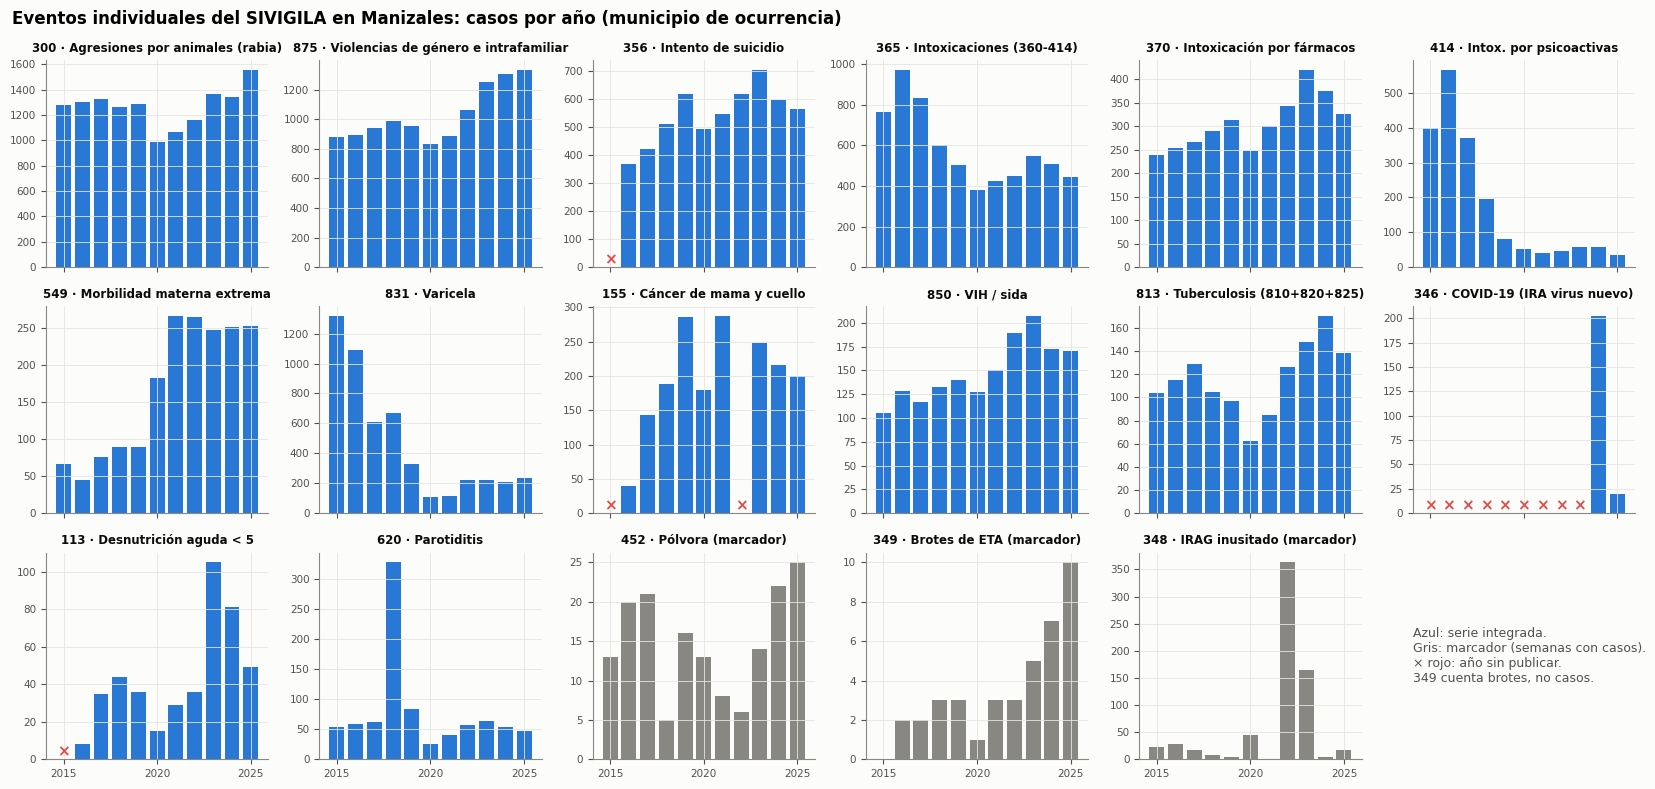

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
300 Agresiones por animales (rabia),1281,1304,1326,1265,1286,984,1069,1163,1364,1345,1555
875 Violencias de género e intrafamiliar,881,893,943,991,953,830,887,1060,1255,1308,1332
356 Intento de suicidio,<NA>,368,422,511,619,493,546,618,703,596,566
365 Intoxicaciones (360-414),767,971,833,603,502,379,423,447,548,510,444
370 Intoxicación por fármacos,239,254,266,289,312,248,300,342,419,375,325
414 Intox. por psicoactivas,399,565,371,194,81,52,41,47,58,58,35
549 Morbilidad materna extrema,66,45,76,90,89,183,266,265,247,251,253
831 Varicela,1316,1089,611,668,328,110,114,224,222,211,237
155 Cáncer de mama y cuello,<NA>,40,143,189,286,180,287,<NA>,248,216,200
850 VIH / sida,105,128,117,133,140,127,151,189,207,173,170


In [5]:
ELEGIDOS = [300, 875, 356, 365, 370, 414, 549, 831, 155, 850, 813, 346, 113, 620, 452, 349, 348]
nombre = {300: "Agresiones por animales (rabia)", 875: "Violencias de género e intrafamiliar", 356: "Intento de suicidio",
          365: "Intoxicaciones (360-414)", 370: "Intoxicación por fármacos", 414: "Intox. por psicoactivas",
          549: "Morbilidad materna extrema", 831: "Varicela", 155: "Cáncer de mama y cuello", 850: "VIH / sida",
          813: "Tuberculosis (810+820+825)", 346: "COVID-19 (IRA virus nuevo)", 113: "Desnutrición aguda < 5",
          620: "Parotiditis", 452: "Pólvora (marcador)", 349: "Brotes de ETA (marcador)", 348: "IRAG inusitado (marcador)"}
em = eve[eve.ambito == "manizales"]
def anual(cod):
    var = "brotes" if cod == 349 else "casos_ocurrencia"
    return em[(em.evento == cod) & (em.variable == var)].groupby("anio").valor.sum().reindex(range(2015, 2026))
AE = pd.DataFrame({c: anual(c) for c in ELEGIDOS})
fig, axes = plt.subplots(3, 6, figsize=(17, 8), sharex=True)
for ax, c in zip(axes.flat, ELEGIDOS):
    marcador = c in (452, 349, 348)
    ax.bar(AE.index, AE[c], color=MUDO if marcador else AZUL, width=.8)
    faltan = AE.index[AE[c].isna()]
    for a in faltan:
        ax.text(a, 0, "×", ha="center", va="bottom", color=ROJO, fontsize=11, fontweight="bold")
    ax.set_title(f"{c} · {nombre.get(c, '')}", fontsize=8.5); ax.tick_params(labelsize=7.5)
for ax in axes.flat[len(ELEGIDOS):]:
    ax.axis("off")
axes.flat[-1].text(0, .5, transform=axes.flat[-1].transAxes, s="Azul: serie integrada.\nGris: marcador (semanas con casos).\n× rojo: año sin publicar.\n349 cuenta brotes, no casos.",
                   fontsize=9, color=TINTA2, va="center")
for ax in axes[-1]:
    ax.set_xticks([2015, 2020, 2025])
fig.suptitle("Eventos individuales del SIVIGILA en Manizales: casos por año (municipio de ocurrencia)", fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
AE.T.rename(index=lambda c: f"{c} {nombre.get(c, '')}").astype("Int64")

## Lectura

**Casi todos los eventos tienen al menos un escalón. Ninguno se puede usar sin mirar su serie.**

| Evento | Escalón | Lo que probablemente es |
|---|---|---|
| 831 Varicela | 1.316 (2015) → 110 (2020): **−92 %** | vacunación y pandemia [I] |
| 414 Psicoactivas | 565 (2016) → 41 (2021): **−93 %**. Arrastra al 365: 971 → 423 | cambio de definición o de notificación [I] |
| 549 Morbilidad materna extrema | 89 (2019) → 183 (2020) → 266 (2021): **×3** | cambio de notificación [I]; en el país también sube |
| 113 Desnutrición < 5 años | 36 (2022) → 105 (2023): **×2,9** | sin explicar |
| 155 Cáncer de mama y cuello | empieza en 2016 con 40; **2022 no está publicado** | hueco del portal |
| 348 IRAG inusitado | 363 (2022) y 164 (2023), contra 1-45 los demás años | la ficha absorbió COVID |
| 346 COVID-19 | solo 2024-2025: 202 y 20 | la ficha nace en 2024 |
| 620 Parotiditis | brote de 2018: 328 | brote real |
| 300 Agresiones por animales | 1.286 (2019) → 984 (2020) | pandemia |
| 875 Violencias | 881 (2015) → 1.332 (2025): **+51 %** | crecimiento sostenido |

**Otro escalón que no se ve en los totales:** el INS cambia, por evento y por año, **qué fecha
define la semana** (notificación, inicio de síntomas o consulta). Por ejemplo, el 875 pasa a fecha
de consulta en 2020 y el 549 en 2023 (tabla en `VIGILANCIA.md`). El total anual no cambia; la
semana de cada caso, sí. Para el histórico existe `casos_ocurrencia_semana_consulta`, con la misma
definición todos los años, pero no existe para 2026.

**Qué pueden sostener.** Totales por año y formas de temporada **dentro** de un régimen estable.
**Qué no:** comparaciones que crucen un escalón, ni el análisis semana a semana en un evento cuya
definición de semana cambió.

## 2.4 Power BI del INS: la vía para 2026

**Qué es.** El tablero público «006 Vigilancia Rutinaria» del INS, publicado con *Publish to web*,
más un tablero por evento. Da conteos por evento × semana × municipio.

- **Publica:** INS. La dirección del tablero y su clave se leen en cada corrida de la lista
  SharePoint `MenuReporteNivel2` de `portalsivigila.ins.gov.co` (detalle en `FUENTES_VIGILANCIA.md`).
- **Se rehace con** `python calendarios/vigilancia/powerbi.py`, que **congela** la descarga del día
  en su carpeta. No se puede rehacer después: el tablero se sobrescribe cada semana.
- **Rezago: ~7 días.** Las 2-3 últimas semanas se revisan por notificación tardía.
- **La API no está documentada.** Solo se piden medidas agregadas: los modelos por evento exponen
  columnas identificables, que nunca se consultan.

La figura compara la IRA del tablero 995 con la de los microdatos, semana a semana y por año.

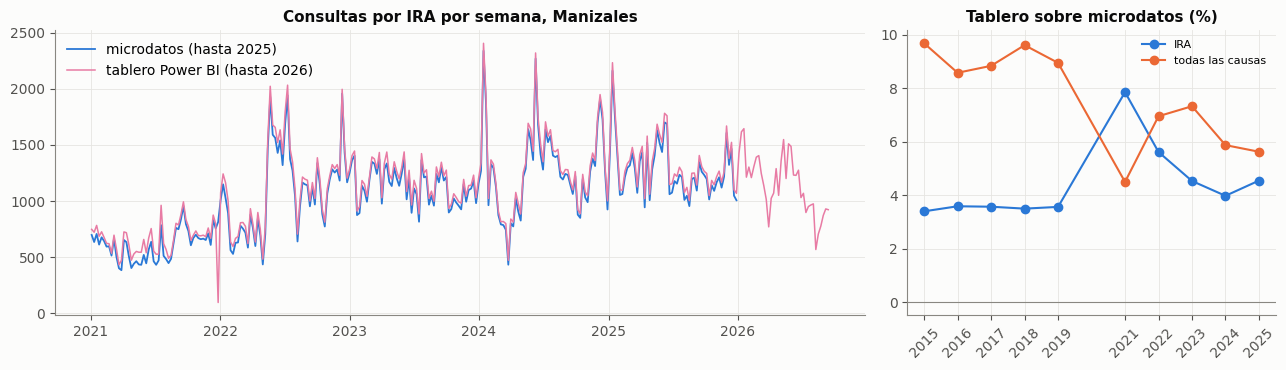

años del tablero 995: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]
semana a semana, 2015-2025: r = 0.994; semanas idénticas: 0 de 521
semanas donde el tablero queda más por debajo de los microdatos: {'2021-12-26': '96 contra 814', '2015-01-04': '1489 contra 1604', '2017-09-17': '1669 contra 1645'}
2026: tablero 995 42,623 IRA en 37 semanas; tabla 995 del 006 40,596 en 37 semanas (-4.8 %)


anio,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
IRA,3.4,3.6,3.6,3.5,3.6,7.9,5.6,4.5,4.0,4.6
todas las causas,9.7,8.6,8.8,9.6,8.9,4.5,7.0,7.3,5.9,5.6


In [6]:
tb = pbi["ira_995_tablero"].copy()
tb["fecha"] = [inicio_semana_epi(a, s) for a, s in zip(tb.anio, tb.semana)]
tb = tb.set_index("fecha").sort_index()
mi_sem = m995[m995.variable == "consultas_ira_total"].set_index("fecha_inicio_semana").valor.sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(mi_sem.loc["2021":].index, mi_sem.loc["2021":], color=AZUL, lw=1.3, label="microdatos (hasta 2025)")
axes[0].plot(tb.loc["2021":].index, tb.loc["2021":, "grup_total"], color=MAGENTA, lw=1.1, label="tablero Power BI (hasta 2026)")
axes[0].set_title("Consultas por IRA por semana, Manizales"); axes[0].legend(loc="upper left")
emp = pd.DataFrame({"IRA": tb.groupby("anio").grup_total.sum() / ira - 1,
                    "todas las causas": tb.groupby("anio").Tot_tot.sum() / todas - 1}).dropna() * 100
axes[1].plot(emp.index, emp["IRA"], "o-", color=AZUL, label="IRA")
axes[1].plot(emp.index, emp["todas las causas"], "o-", color=NARANJA, label="todas las causas")
axes[1].axhline(0, color=MUDO, lw=.8); axes[1].set_title("Tablero sobre microdatos (%)"); axes[1].legend(fontsize=8)
axes[1].set_xticks(emp.index, emp.index, rotation=45)
plt.tight_layout(); plt.show()
r_sem = pd.concat([mi_sem, tb.grup_total], axis=1, keys=["m", "t"]).dropna()
print(f"años del tablero 995: {sorted(tb.anio.unique())}")
print(f"semana a semana, 2015-2025: r = {r_sem.m.corr(r_sem.t):.3f}; semanas idénticas: {(r_sem.m == r_sem.t).sum()} de {len(r_sem)}")
peores = (r_sem.t / r_sem.m - 1).mul(100).sort_values().head(3)
print("semanas donde el tablero queda más por debajo de los microdatos:",
      {f"{d:%Y-%m-%d}": f"{int(r_sem.t[d])} contra {int(r_sem.m[d])}" for d in peores.index})
r26 = pbi["ira_995_rutinaria"]
print(f"2026: tablero 995 {int(tb.loc[tb.anio == 2026, 'grup_total'].sum()):,} IRA en {int((tb.anio == 2026).sum())} semanas; "
      f"tabla 995 del 006 {int(r26.consultas_ira.sum()):,} en {len(r26)} semanas "
      f"({100 * (r26.consultas_ira.sum() / tb.loc[tb.anio == 2026, 'grup_total'].sum() - 1):+.1f} %)")
emp.round(1).T

In [7]:
filas = []
for k in ["300", "356", "831", "875"]:
    t = pbi[f"evento_{k}"].groupby("anio").casos.sum()
    m = anual(int(k))
    for a in range(2022, 2026):
        filas.append({"evento": int(k), "año": a, "tablero": int(t.get(a, 0)), "microdatos": int(m.get(a, 0)),
                      "diferencia %": round(100 * (t.get(a, 0) / m.get(a, np.nan) - 1), 1)})
E = pd.DataFrame(filas)
display(E.pivot(index="evento", columns="año", values="diferencia %"))
top = rut.groupby(["cod_eve", "nom_eve"]).casos.sum().sort_values(ascending=False)
print(f"006 de 2026, Manizales: {rut.cod_eve.nunique()} eventos, {int(rut.casos.sum()):,} casos, SE1 a SE{rut.semana.max()}")
top.head(10).rename(lambda s: s[:45] if isinstance(s, str) else s).to_frame("casos 2026")

año,2022,2023,2024,2025
evento,,,,
300,-1.2,-0.1,-8.3,-1.1
356,-1.0,1.1,0.8,1.6
831,1.3,-0.9,1.4,-0.4
875,0.3,1.5,0.4,-0.3


006 de 2026, Manizales: 28 eventos, 3,747 casos, SE1 a SE38


,,casos 2026
cod_eve,nom_eve,
300,AGRESIONES POR ANIMALES POTENCIALMENTE TRANSM,1102
875,VIGILANCIA EN SALUD PÚBLICA DE LA VIOLENCIA D,901
356,INTENTO DE SUICIDIO,472
365,INTOXICACIONES,344
549,MORBILIDAD MATERNA EXTREMA,216
155,CÁNCER DE LA MAMA Y CUELLO UTERINO,148
831,VARICELA INDIVIDUAL,144
850,VIH/SIDA/MORTALIDAD POR SIDA,102
813,TUBERCULOSIS,80


## Lectura

**El tablero cuadra en la forma y no en el nivel.**

- **IRA del tablero 995: +3,4 a +7,9 % por encima de los microdatos todos los años.** Todas las
  causas, +4,5 a +9,7 %. Semana a semana, r = 0,994 y **ninguna de 521 semanas es idéntica**: es un
  nivel, no un desfase. Para empalmar 2026 hace falta un factor de nivel por año, o usar la
  proporción, que ya es cociente.
- **Hay una semana rota en el tablero:** la que empieza el 2021-12-26 (SE52 de 2021) da 96 consultas
  contra 814 en los microdatos. Es la caída que se ve a principios de 2022 en la figura.
- **Dentro de 2026, dos tablas del mismo INS no coinciden:** el tablero 995 da 42.623 IRA en 37
  semanas y la tabla 995 del 006, 40.596 (−4,8 %).
- **Eventos por tablero contra microdatos:** dentro del ±1,6 % por año en 356, 831 y 875, salvo el
  **300 de 2024, −8,3 %**, sin explicar.
- **El 006 de 2026** trae 28 eventos y 3.747 casos de Manizales, de la SE1 a la SE38.

**Límites.**
- Hay **una sola instantánea** (2026-09-28). Sin una tarea que congele una cada semana, no se puede
  evaluar el pronóstico «con lo que se sabía en su momento».
- **Qué semana usa el 006 no está verificado**: los tableros por evento no usan todos la misma
  definición (`VIGILANCIA.md`).

---
# 3. Clima

**Qué es.** Una fila por día con temperatura, lluvia, humedad, viento y radiación. Une cuatro fuentes:
cada variable tiene una referencia medida en Manizales, y las demás se llevan a su escala mes a
mes antes de tomar la mediana.

| Fuente | Quién la publica | Dónde |
|---|---|---|
| Estaciones IDEAM (Tesorito, 7,7 km; La Nubia, 5,0 km) | IDEAM | datos.gov.co, `s54a-sgyg` (precipitación) y `sbwg-7ju4` (temperatura) |
| METAR del aeropuerto La Nubia (SKMZ) | Aerocivil, vía Iowa Environmental Mesonet | `https://mesonet.agron.iastate.edu/api/1/daily.txt` |
| Reanálisis ERA5-Land / ERA5 | Copernicus, vía Open-Meteo | `https://archive-api.open-meteo.com/v1/archive` |
| Reanálisis MERRA-2 / satélite | NASA POWER | `https://power.larc.nasa.gov/api/temporal/daily/point` |

- **Se rehace con** `python calendarios/clima/clima_manizales.py` (descarga) y
  `python calendarios/clima/clima_unificado.py` (une y audita).
- **Rezago:** días.
- **Referencia de la lluvia: el pluviómetro IDEAM.** Donde falta, se usa NASA escalado al mes, que
  acierta el total del mes pero no el día (r = 0,18). La columna `precip_con_estacion` dice qué días
  tienen pluviómetro. Método y evidencia: `calendarios/docs/CLIMA.md`.
- **Desde el 2026-09-29, la columna `pluviometro_fallido`** marca los días en que el pluviómetro
  reporta (casi) cero mientras NASA registra lluvia; esos días se tratan como sin pluviómetro. Es la
  corrección de lo que esta sección encontró (ver la lectura y la sección 3.1).
- **Es clima observado.** Para pronosticar de verdad hará falta el pronóstico archivado
  (Open-Meteo), que es candidato y no está integrado.

La primera figura mira la **medida en tierra** que hay debajo del consenso.
- Panel 2: para cada mes, la lluvia que sumó el pluviómetro en sus días válidos, contra la que dio
  NASA **esos mismos días**. Las dos no tienen por qué coincidir en nivel (NASA llueve casi el doble),
  pero sí deben subir y bajar juntas.

*(Añadido el 2026-09-29.)* El archivo corregido ya no guarda la lectura del pluviómetro en los días
de falla. Para poder seguir viéndola, la celda rehace la unión con el mismo script **sin la
detección** (`antes`), y comprueba que con la detección puesta sale idéntico al archivo actual. La
figura y las tablas de esta celda usan esa **lectura cruda**; en rojo, los días que ahora se
descartan. La tabla por año trae al final las dos columnas del clima corregido.

comprobación: la unión rehecha con la detección da el archivo actual; diferencia máxima del consenso = 3.6e-15 mm


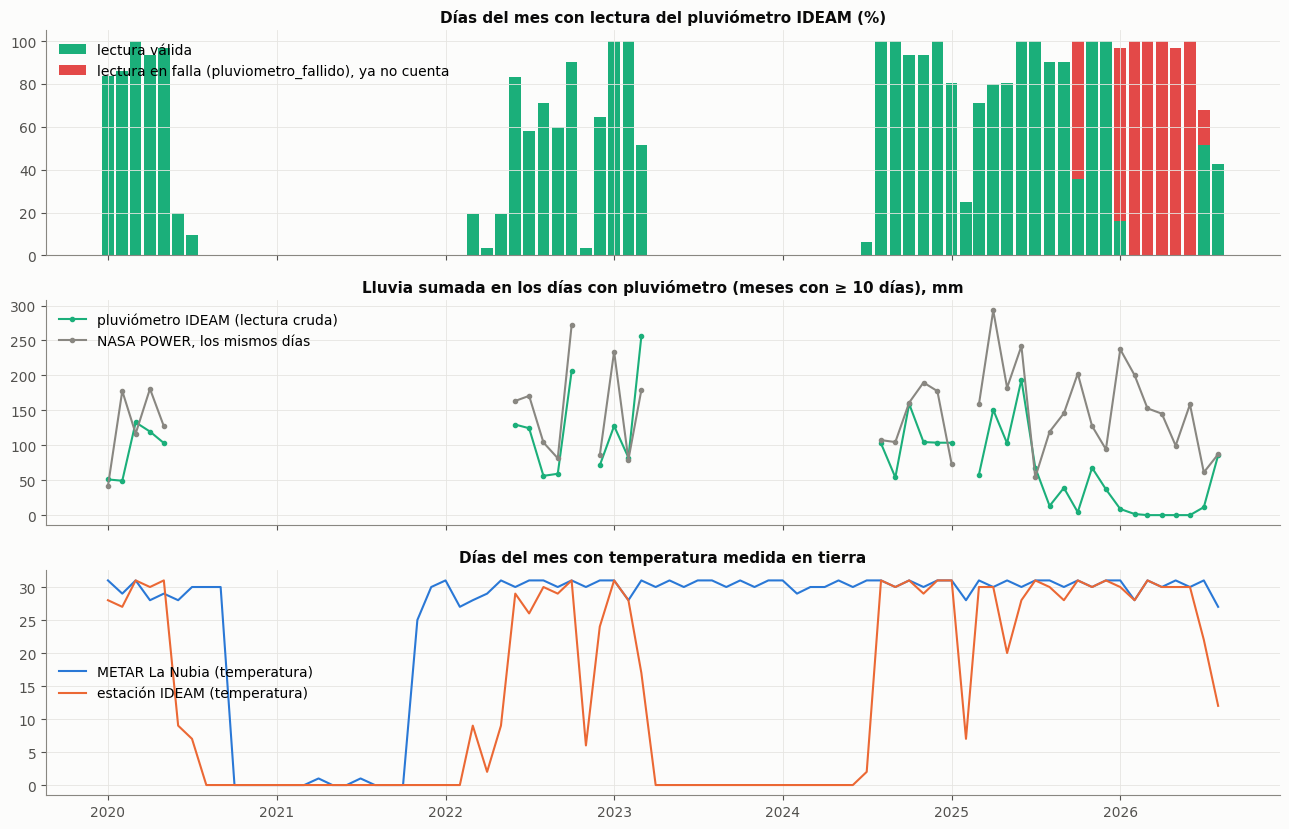

último día con ≥ 1 mm en el pluviómetro (crudo) antes de julio de 2026: 2026-01-02


fecha,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
días de estación,31,28,27,31,30,31,30,28,31,30,30,30,21,12
pluviómetro mm,68,13,39,4,67,37,8,1,0,0,0,0,11,85
"NASA mm, mismos días",54,119,145,202,127,94,237,200,152,145,99,158,61,87
días marcados como falla,0,0,0,20,0,0,25,28,31,30,30,30,5,0


,% días con pluviómetro,"pluviómetro / NASA, mismos días",r diaria pluviómetro-NASA,% días con ≥ 1 mm en el pluviómetro,lluvia consenso mm,"% días con pluviómetro, corregido","lluvia consenso mm, corregida",días METAR,días en el archivo
fecha,,,,,,,,,
2020,40.71,0.71,0.29,38.93,937.43,40.71,1073.67,266,366
2021,0.00,NaN,NaN,NaN,664.23,0.00,828.36,57,365
2022,39.73,0.75,0.49,64.14,1460.13,39.73,1728.52,360,365
2023,20.55,0.95,0.23,54.67,1178.10,20.55,1390.07,365,365
2024,41.26,0.72,0.29,35.10,1180.62,41.26,1423.87,365,366
2025,85.21,0.49,0.12,35.37,1063.02,79.73,1309.55,365,365
2026,88.33,0.09,0.25,3.77,403.63,13.75,875.11,239,240


In [8]:
# Desde el 2026-09-29 el archivo ya no trae la lectura del pluviometro en los dias de falla (la
# pone en NaN). Para ver la falla hay que rehacer la union SIN la deteccion: es el mismo script, con
# pluviometro_fallido desactivado, y reproduce exactamente el archivo anterior a la correccion.
sys.path.insert(0, str(CAL / "clima"))
import clima_unificado as cu
_detector = cu.pluviometro_fallido
cu.pluviometro_fallido = lambda c: pd.Series(False, index=c.index)
try:
    antes = cu.unir().set_index("fecha").reindex(clima.index)      # el clima tal como estaba antes del 29-09
finally:
    cu.pluviometro_fallido = _detector
crudo = antes.precipitacion_mm                                       # el pluviometro tal como lo reporta IDEAM
print("comprobación: la unión rehecha con la detección da el archivo actual; diferencia máxima del consenso =",
      f"{(cu.unir().set_index('fecha').reindex(clima.index).precip_consenso_mm - clima.precip_consenso_mm).abs().max():.1e} mm")

est = crudo.notna()                                                  # dia con lectura del pluviometro (crudo)
mes = clima.index.to_period("M")
M = pd.DataFrame({
    "% días con pluviómetro": 100 * est.groupby(mes).mean(),
    "pluviómetro mm": crudo.where(est).groupby(mes).sum(),
    "NASA mm, mismos días": clima.np_PRECTOTCORR.where(est).groupby(mes).sum(),
    "días marcados como falla": FALLA.groupby(mes).sum(),
    "días de estación": est.groupby(mes).sum(),
    "días METAR": clima.iem_tmedia_c.notna().groupby(mes).sum(),
    "días IDEAM temp.": clima.temp_media.notna().groupby(mes).sum()})
M.index = M.index.to_timestamp()
fig, axes = plt.subplots(3, 1, figsize=(13, 8.4), sharex=True)
pct_falla = 100 * M["días marcados como falla"] / M.index.days_in_month
axes[0].bar(M.index, M["% días con pluviómetro"] - pct_falla, width=25, color=AQUA, label="lectura válida")
axes[0].bar(M.index, pct_falla, bottom=M["% días con pluviómetro"] - pct_falla, width=25, color=ROJO,
            label="lectura en falla (pluviometro_fallido), ya no cuenta")
axes[0].set_title("Días del mes con lectura del pluviómetro IDEAM (%)"); axes[0].set_ylim(0, 105); axes[0].legend(loc="upper left")
ok = M["días de estación"] >= 10
axes[1].plot(M.index, M["pluviómetro mm"].where(ok), "o-", ms=3, color=AQUA, label="pluviómetro IDEAM (lectura cruda)")
axes[1].plot(M.index, M["NASA mm, mismos días"].where(ok), "o-", ms=3, color=MUDO, label="NASA POWER, los mismos días")
axes[1].set_title("Lluvia sumada en los días con pluviómetro (meses con ≥ 10 días), mm"); axes[1].legend(loc="upper left")
axes[2].plot(M.index, M["días METAR"], color=AZUL, label="METAR La Nubia (temperatura)")
axes[2].plot(M.index, M["días IDEAM temp."], color=NARANJA, label="estación IDEAM (temperatura)")
axes[2].set_title("Días del mes con temperatura medida en tierra"); axes[2].legend(loc="center left", ncol=1)
axes[2].xaxis.set_major_locator(mdates.YearLocator()); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

anio = clima.index.year
dc = pd.DataFrame({"p": crudo, "n": clima.np_PRECTOTCORR})
Y = pd.DataFrame({"% días con pluviómetro": 100 * est.groupby(anio).mean(),
                  "pluviómetro / NASA, mismos días": crudo.where(est).groupby(anio).sum() / clima.np_PRECTOTCORR.where(est).groupby(anio).sum(),
                  "r diaria pluviómetro-NASA": [dc[anio == a].dropna().corr().iloc[0, 1] if est[anio == a].sum() > 20 else np.nan for a in sorted(set(anio))],
                  "% días con ≥ 1 mm en el pluviómetro": 100 * (crudo >= 1).groupby(anio).sum() / est.groupby(anio).sum(),
                  "lluvia consenso mm": antes.precip_consenso_mm.groupby(anio).sum(),
                  "% días con pluviómetro, corregido": 100 * clima.precip_con_estacion.groupby(anio).mean(),
                  "lluvia consenso mm, corregida": clima.precip_consenso_mm.groupby(anio).sum(),
                  "días METAR": clima.iem_tmedia_c.notna().groupby(anio).sum(),
                  "días en el archivo": anio.value_counts().sort_index()}).round(2)
ultimo = crudo.loc[:"2026-06-30"]
print("último día con ≥ 1 mm en el pluviómetro (crudo) antes de julio de 2026:", f"{ultimo[ultimo >= 1].index.max():%Y-%m-%d}")
sin_lluvia = M.loc["2025-07":"2026-08", ["días de estación", "pluviómetro mm", "NASA mm, mismos días", "días marcados como falla"]]
display(sin_lluvia.astype(int).T)
Y

## Lectura

**Hallazgo nuevo: desde octubre de 2025 el pluviómetro de La Nubia reporta casi cero, y el
archivo lo trata como dato bueno.**

| Mes | 2025-10 | 2026-01 | 2026-02 | 2026-03 | 2026-04 | 2026-05 | 2026-06 | 2026-08 |
|---|---|---|---|---|---|---|---|---|
| Días con pluviómetro | 31 | 30 | 28 | 31 | 30 | 30 | 30 | 12 |
| Pluviómetro, mm | 4 | 8 | 1 | **0** | **0** | **0** | **0** | 85 |
| NASA, mismos días, mm | 202 | 237 | 200 | 152 | 145 | 99 | 158 | 87 |

- **El último día con ≥ 1 mm antes de julio de 2026 es el 2026-01-02.** Cuatro meses enteros de
  la primera temporada de lluvias, de marzo a junio de 2026, en cero exacto.
- Por año, el cociente pluviómetro / NASA en los mismos días era 0,71-0,95 en 2020-2024. Cae a
  **0,49 en 2025 y 0,09 en 2026**. La correlación diaria baja a 0,12 en 2025.
- **La «cobertura» del 85 y el 88 % de 2025 y 2026 es engañosa.** `precip_con_estacion` marca esos
  días como medidos, así que el consenso los toma como referencia.
- En agosto de 2026 vuelve a coincidir con NASA (85 contra 87 mm): la estación parece reparada.

**Otros dos huecos de la medida en tierra:**
- **En 2021 no hay ni un día de pluviómetro, y solo 57 de METAR.** Todo 2021 es reanálisis.
- Sin pluviómetro también de abril de 2023 a junio de 2024.

**Consecuencia.** Cualquier variable de lluvia de octubre de 2025 a junio de 2026, sea diaria o
acumulada, está contaminada. Eso incluye las transiciones «seco → lluvioso». La corrección
(tratar esos días como sin pluviómetro en `clima_unificado.py`) **no se hace en este cuaderno**:
queda señalada.

> **Corrección del 2026-09-29 (clima corregido).** La corrección señalada ya está hecha en
> `clima_unificado.py` (sección 3.1). La tabla del mes, medida sobre la lectura cruda, **no cambia**:
> sigue siendo la evidencia de la falla. Lo que cambia es lo que el archivo hace con ella:
> - **% de días con pluviómetro: 2025, 85,2 → 79,7 %; 2026, 88,3 → 13,8 %.** La «cobertura» engañosa
>   de 2026 desaparece: casi todo 2026 pasa a ser NASA escalado;
> - **lluvia anual del consenso: 2025, 1.063 → 1.310 mm; 2026 (hasta agosto), 404 → 875 mm**;
> - y sube **todo** el nivel, también en los años sin falla: 2020, 937 → 1.074; 2021, 664 → 828;
>   2022, 1.460 → 1.729; 2023, 1.178 → 1.390; 2024, 1.181 → 1.424 mm (+15 a +25 %). No es que
>   lloviera más: los ceros de la falla entraban en el factor con que se escala NASA a la escala del
>   pluviómetro, que se calcula **por mes del calendario**, y lo encogían en todos los años. Por eso
>   la subida se concentra en enero a julio y en octubre, los meses que tuvieron días en falla;
>   agosto, septiembre, noviembre y diciembre quedan iguales (tabla de la sección 3.2).
> - Julio de 2026 (5 días) también queda marcado; agosto de 2026 no, y coincide con NASA.

## 3.1 La falla, detectada: `pluviometro_fallido`

*(Sección añadida el 2026-09-29.)* El criterio, fijado en `clima_unificado.py` antes de regenerar el
archivo (`docs/CONTEXTO.md`, 2026-09-29): un día se marca como falla cuando, **en los 31 días
centrados en él**, el pluviómetro suma menos del **10 %** de lo que suma NASA en los mismos días, y NASA
suma al menos **60 mm**. La ventana es de un mes y no de un día a propósito: un día seco aislado es
real; un mes entero en cero mientras el satélite ve lluvia, no.

La figura dibuja las dos condiciones en la lectura cruda, de julio de 2024 a agosto de 2026. En
sombreado, los días que el script marca.

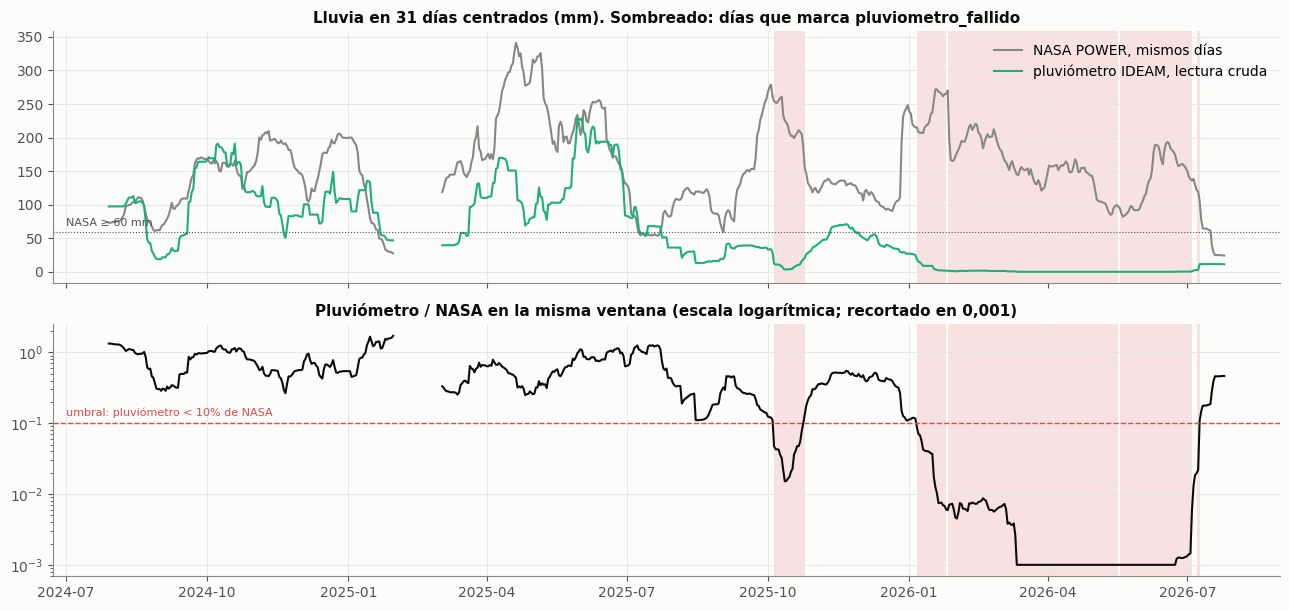

meses sanos (29): razón pluviómetro/NASA de 0.11 a 1.43, mediana 0.73
meses con ≥ 15 días en falla (7): razón de 0.000 a 0.037
días marcados: 199  (primero 2025-10-05, último 2026-07-08)


fecha,2025-10,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
días en falla,20,25,28,31,30,30,30,5


In [9]:
# El criterio de clima_unificado.pluviometro_fallido, dibujado: sumas de 31 dias centrados en los dias
# con lectura del pluviometro y de NASA a la vez.
ambos = crudo.notna() & clima.np_PRECTOTCORR.notna()
vent = dict(window=cu.FALLA_VENTANA_DIAS, center=True, min_periods=15)
s_p = crudo.where(ambos).rolling(**vent).sum()
s_n = clima.np_PRECTOTCORR.where(ambos).rolling(**vent).sum()
V0, V1 = "2024-07-01", "2026-08-31"
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
for ax in axes:
    for ini, dur in tramos(FALLA.loc[V0:V1]):
        ax.axvspan(ini, ini + dur, color=ROJO, alpha=.14, lw=0)
axes[0].plot(s_n.loc[V0:V1].index, s_n.loc[V0:V1], color=MUDO, label="NASA POWER, mismos días")
axes[0].plot(s_p.loc[V0:V1].index, s_p.loc[V0:V1], color=AQUA, label="pluviómetro IDEAM, lectura cruda")
axes[0].axhline(cu.FALLA_NASA_MINIMA_MM, color=TINTA2, lw=.8, ls=":")
axes[0].text(pd.Timestamp(V0), cu.FALLA_NASA_MINIMA_MM + 8, f"NASA ≥ {cu.FALLA_NASA_MINIMA_MM:.0f} mm", fontsize=8, color=TINTA2)
axes[0].set_title("Lluvia en 31 días centrados (mm). Sombreado: días que marca pluviometro_fallido"); axes[0].legend(loc="upper right")
razon = (s_p / s_n).where(s_n > 0)
axes[1].plot(razon.loc[V0:V1].index, razon.loc[V0:V1].clip(lower=1e-3), color=TINTA)
axes[1].axhline(cu.FALLA_RAZON_MAXIMA, color=ROJO, lw=1, ls="--")
axes[1].text(pd.Timestamp(V0), cu.FALLA_RAZON_MAXIMA * 1.25, f"umbral: pluviómetro < {cu.FALLA_RAZON_MAXIMA:.0%} de NASA", fontsize=8, color=ROJO)
axes[1].set_yscale("log"); axes[1].set_title("Pluviómetro / NASA en la misma ventana (escala logarítmica; recortado en 0,001)")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

# razon mensual en los meses con >= 15 dias con lectura, sanos contra fallidos
mm = clima.index.to_period("M")
RM = pd.DataFrame({"dias": ambos.groupby(mm).sum(), "falla": FALLA.groupby(mm).sum(),
                   "razon": crudo.where(ambos).groupby(mm).sum() / clima.np_PRECTOTCORR.where(ambos).groupby(mm).sum()})
RM = RM[RM.dias >= 15]
sanos, fallidos = RM[RM.falla == 0].razon, RM[RM.falla >= 15].razon
print(f"meses sanos ({len(sanos)}): razón pluviómetro/NASA de {sanos.min():.2f} a {sanos.max():.2f}, mediana {sanos.median():.2f}")
print(f"meses con ≥ 15 días en falla ({len(fallidos)}): razón de {fallidos.min():.3f} a {fallidos.max():.3f}")
print(f"días marcados: {FALLA.sum()}  (primero {FALLA[FALLA].index.min():%Y-%m-%d}, último {FALLA[FALLA].index.max():%Y-%m-%d})")
FALLA.groupby(mm).sum()[lambda s: s > 0].rename("días en falla").to_frame().T

## Lectura

**La falla se separa de la lluvia normal por un orden de magnitud.**

| | Meses | Razón pluviómetro / NASA |
|---|---|---|
| Sin ningún día marcado (con ≥ 15 días de lectura) | 29 | 0,11 a 1,43; mediana 0,73 |
| Con ≥ 15 días marcados | 7 | **0,000 a 0,037** |

- **199 días marcados, del 2025-10-05 al 2026-07-08**: 20 en octubre de 2025, 25 en enero de 2026,
  todos los de febrero a junio y 5 en julio. Noviembre y diciembre de 2025 quedan fuera: el
  pluviómetro volvió a medir (0,53 y 0,39 de NASA).
- En el panel de abajo, la razón pasa de la franja 0,3-1,3 a menos de 0,01 y se queda ahí de febrero
  a junio de 2026. En julio sube de golpe: la estación vuelve.

**Límite.** Agosto de 2025 no se marca y está **a una centésima del umbral**: 13 mm de pluviómetro
contra 119 de NASA, razón 0,111. Puede ser un mes seco de verdad en la estación o el comienzo de la
falla; el criterio no lo distingue, y queda como dato de pluviómetro.

## 3.2 La serie de lluvia, antes y después de la corrección

La lluvia del consenso, mes a mes, por año. Si la estación rota arrastra al consenso, 2026 debe
salir como un año seco sin serlo. Al final se revisan los episodios «seco → lluvioso» del cuaderno
07 (misma definición) cuya ventana de 28 días toca un mes con el pluviómetro en cero.

*(Ajustado el 2026-09-29.)* La figura y la tabla son ya del **clima corregido**; la línea roja
discontinua es 2026 tal como estaba antes. Los episodios se cuentan con los dos climas, para ver
cuáles se mantienen, cuáles desaparecen y cuáles aparecen.

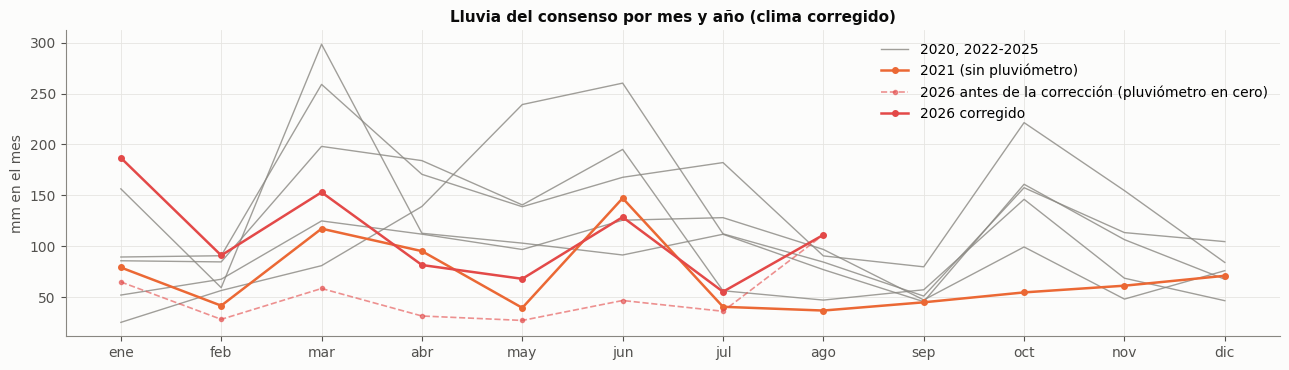

episodios seco -> lluvioso (definición del 07), clima de antes: 13; con días en falla en sus 28 días: ['2026-01-12']
episodios con el clima corregido: 17
  se mantienen: ['2022-09-15', '2023-02-19', '2023-07-06', '2023-08-22', '2023-10-07', '2023-12-17', '2024-02-04', '2024-04-03', '2024-08-07', '2024-09-26', '2025-09-19']
  desaparecen:  ['2023-01-01', '2026-01-12']
  aparecen:     ['2022-07-26', '2023-01-05', '2025-01-05', '2026-01-11', '2026-06-24', '2026-08-21']

lluvia del consenso por mes, octubre de 2025 a agosto de 2026 (mm):


fecha,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
antes,61,69,46,65,28,58,31,27,47,36,111
corregido,146,69,46,187,91,153,81,68,129,55,111


anio,2020,2021,2022,2023,2024,2025,2026
mes,,,,,,,
1,52,79,89,156,25,86,187
2,68,42,91,59,56,85,91
3,125,117,259,298,81,198,153
4,112,95,171,113,139,184,81
5,97,39,139,103,239,141,68
6,126,147,168,91,260,195,129
7,128,40,182,112,112,56,55
8,97,37,90,77,84,47,111
9,47,45,80,45,51,57,<NA>


In [10]:
C = clima.precip_consenso_mm.resample("MS").sum(min_count=20).to_frame("mm")
C["anio"], C["mes"] = C.index.year, C.index.month
P = C.pivot(index="mes", columns="anio", values="mm")
A = antes.precip_consenso_mm.resample("MS").sum(min_count=20).to_frame("mm")
A["anio"], A["mes"] = A.index.year, A.index.month
PA = A.pivot(index="mes", columns="anio", values="mm")
fig, ax = plt.subplots(figsize=(13, 3.8))
for a in P.columns:
    if a in (2021, 2026):
        continue
    ax.plot(P.index, P[a], color=MUDO, lw=1, alpha=.8, label="2020, 2022-2025" if a == 2020 else None)
ax.plot(P.index, P[2021], "o-", color=NARANJA, lw=1.8, ms=4, label="2021 (sin pluviómetro)")
ax.plot(PA.index, PA[2026], "o--", color=ROJO, lw=1.2, ms=3, alpha=.6, label="2026 antes de la corrección (pluviómetro en cero)")
ax.plot(P.index, P[2026], "o-", color=ROJO, lw=1.8, ms=4, label="2026 corregido")
ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("mm en el mes"); ax.set_title("Lluvia del consenso por mes y año (clima corregido)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# los episodios "seco -> lluvioso" del cuaderno 07 (misma definicion), con el clima de antes y con el corregido
def episodios(serie):
    pr = serie.reindex(pd.date_range("2020-01-01", "2026-09-20"))
    p7, p21 = pr.rolling(7).sum(), pr.shift(7).rolling(21).sum() / 3
    z = lambda x: (x - x.groupby(x.index.month).transform("mean")) / x.groupby(x.index.month).transform("std")
    senal = (z(p7) >= 1) & (z(p21) <= -.5)
    ep, ult = [], None
    for d in senal[senal].index:
        if ult is None or (d - ult).days >= 28:
            ep.append(d); ult = d
    return [d for d in ep if pd.Timestamp("2022-03-01") <= d <= pd.Timestamp("2026-08-23")]
ep_a, ep_d = episodios(antes.precip_consenso_mm), episodios(clima.precip_consenso_mm)
f = lambda L: [f"{d:%Y-%m-%d}" for d in L]
malos = [d for d in ep_a if FALLA.loc[d - pd.Timedelta(days=27):d].any()]
print(f"episodios seco -> lluvioso (definición del 07), clima de antes: {len(ep_a)}; con días en falla en sus 28 días: {f(malos)}")
print(f"episodios con el clima corregido: {len(ep_d)}")
print("  se mantienen:", f(sorted(set(ep_a) & set(ep_d))))
print("  desaparecen: ", f(sorted(set(ep_a) - set(ep_d))))
print("  aparecen:    ", f(sorted(set(ep_d) - set(ep_a))))
print("\nlluvia del consenso por mes, octubre de 2025 a agosto de 2026 (mm):")
display(pd.DataFrame({"antes": antes.precip_consenso_mm.resample("MS").sum(), "corregido": clima.precip_consenso_mm.resample("MS").sum()})
        .loc["2025-10":"2026-08"].round(0).astype(int).T.rename(columns=lambda d: f"{d:%Y-%m}"))
P.round(0).astype("Int64")

## Lectura

- **Marzo a junio de 2026 dan 58, 31, 27 y 47 mm: el mes más seco de toda la serie en los cuatro
  casos.** Es la primera temporada de lluvias. NASA, en los mismos días, daba entre 99 y 158 mm al
  mes. Es el pluviómetro en cero arrastrando la mediana, no una sequía.
- **2021 es el año más seco del consenso (664 mm, contra 937-1.460 los demás años completos)** y no
  tiene ninguna medida en tierra. No se puede saber si es real.
- **Uno de los 13 episodios «seco → lluvioso» del cuaderno 07 cae en la zona dañada: el del
  2026-01-12.** Su definición mira los 28 días previos, que incluyen enero de 2026. Los otros 12 no
  tocan los meses marcados. El 07 no se toca aquí; hay que repetirlo sin ese episodio cuando se
  corrija el clima.

**Qué puede sostener el clima.** La temperatura, en todo el periodo; con 2021 apoyado solo en
reanálisis. La lluvia de 2022-2025 en acumulados de 7 días o más.

**Qué no.**
- La lluvia de octubre de 2025 a junio de 2026 mientras no se corrija.
- Transiciones día a día de lluvia en 2021.

> **Corrección del 2026-09-29 (clima corregido).** Con `pluviometro_fallido` en el archivo:
> - **marzo a junio de 2026: 58, 31, 27 y 47 mm → 153, 81, 68 y 129 mm.** Ya no son los meses más secos
>   de la serie en los cuatro casos: marzo y junio quedan dentro del rango de los demás años y mayo
>   por encima de 2021 (39). **Abril sigue siendo el más seco de su mes** (81 contra 95-184), pero ya
>   sin el cero detrás, sobre NASA escalado. También cambian octubre de 2025 (61 → 146), enero (65 → 187), febrero (28 → 91) y
>   julio de 2026 (36 → 55). Noviembre, diciembre y agosto, sin días marcados, no se mueven.
> - **2021 sigue siendo el año más seco (664 → 828 mm, contra 1.074-1.729 los demás años completos)**
>   y sigue sin medida en tierra. Su nivel sube por lo mismo que el de todos: el factor de escala.
> - **Episodios «seco → lluvioso» (definición del 07): 13 → 17.** Se mantienen 11. Dos solo se
>   corren unos días: 2023-01-01 → 2023-01-05 y **2026-01-12 → 2026-01-11** (este sigue, ahora sobre
>   NASA escalado en vez de sobre el pluviómetro en cero). Aparecen cuatro nuevos: 2022-07-26,
>   2025-01-05, 2026-06-24 y 2026-08-21. Los de 2022 y 2025 caen fuera de la falla: aparecen porque
>   el nuevo nivel cambia las medias y desviaciones de cada mes con que se calcula el z.
> - Con esos 17, el cuaderno 07 da para 0-4 años **+13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 %
>   a los 14-20** (antes, +22,0 ± 17,8 % con 13). Conserva la forma, pero **ya no se distingue de
>   cero**.
>
> **Qué puede sostener ahora.** La lluvia de octubre de 2025 a julio de 2026 existe, pero es NASA
> escalado: vale para acumulados de 7 días o más, no para el día exacto. **Qué no:** el nivel de
> lluvia de antes del 29-09 comparado con el de ahora (todo subió un 15-25 %).

---
# 4. Seguridad: delitos y lesiones de MinDefensa

**Qué es.** Delitos registrados por la Policía en Manizales, sumados por día.

- **Publica:** Ministerio de Defensa Nacional, en datos.gov.co:
  - `ntej-qq7v`: lesiones en accidente de tránsito;
  - `uav5-b85g`: homicidio en accidente de tránsito;
  - `jr6v-i33g`: lesiones personales;
  - `m8fd-ahd9`: homicidio;
  - `gepp-dxcs`: violencia intrafamiliar.

  Consulta: `https://www.datos.gov.co/resource/<id>.json?$where=cod_muni='17001'`.
- **Se rehace con** `python calendarios/seguridad/mindefensa.py`. Solo pide sumas por día
  (`$group=fecha_hecho`), nunca una fila suelta.
- **Rezago: 2-6 semanas**, publicación mensual.
- **Mide lo denunciado, no lo ocurrido.**

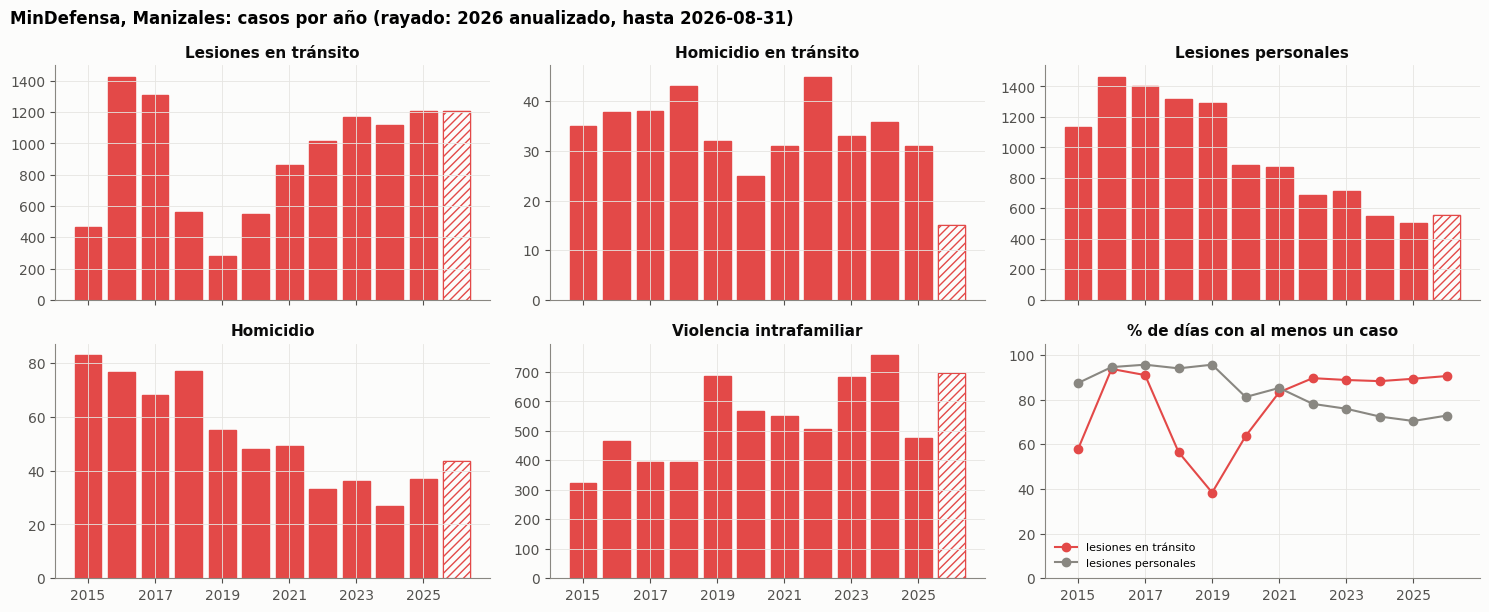

,Lesiones en tránsito,Homicidio en tránsito,Lesiones personales,Homicidio,Violencia intrafamiliar,días con lesión en tránsito (%)
fecha,,,,,,
2015,467,35,1132,83,323,58
2016,1432,38,1469,77,466,94
2017,1313,38,1403,68,394,91
2018,563,43,1319,77,395,56
2019,279,32,1288,55,688,38
2020,550,25,890,48,570,64
2021,862,31,870,49,551,83
2022,1013,45,690,33,505,90
2023,1168,33,711,36,683,89


In [11]:
DEL = {"lesiones_transito": "Lesiones en tránsito", "homicidio_transito": "Homicidio en tránsito",
       "lesiones_personales": "Lesiones personales", "homicidio": "Homicidio", "violencia_intrafamiliar": "Violencia intrafamiliar"}
anual_s = seg.groupby(seg.index.year).sum()
dias_s = seg.groupby(seg.index.year).size()
parcial = dias_s.index[dias_s < 365]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.2), sharex=True)
for ax, (c, t) in zip(axes.flat, DEL.items()):
    v = anual_s[c] * 365 / dias_s                  # 2026 anualizado
    ax.bar(v.index, v, color=[SUP if a in parcial else ROJO for a in v.index], edgecolor=ROJO, hatch=None)
    for a in parcial:
        ax.bar(a, v[a], color=SUP, edgecolor=ROJO, hatch="////", lw=.8)
    ax.set_title(t)
dias_con = (seg > 0).groupby(seg.index.year).mean() * 100
axes.flat[5].plot(dias_con.index, dias_con.lesiones_transito, "o-", color=ROJO, label="lesiones en tránsito")
axes.flat[5].plot(dias_con.index, dias_con.lesiones_personales, "o-", color=MUDO, label="lesiones personales")
axes.flat[5].set_title("% de días con al menos un caso"); axes.flat[5].legend(fontsize=8, loc="lower left"); axes.flat[5].set_ylim(0, 105)
for ax in axes[-1]:
    ax.set_xticks(range(2015, 2027, 2))
fig.suptitle(f"MinDefensa, Manizales: casos por año (rayado: {', '.join(map(str, parcial))} anualizado, hasta {seg.index.max():%Y-%m-%d})",
             fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
out = anual_s.astype(int).copy(); out.columns = [DEL[c] for c in out.columns]
out["días con lesión en tránsito (%)"] = dias_con.lesiones_transito.round(0).astype(int)
out

## Lectura

**Las lesiones en tránsito tienen dos regímenes de registro, no uno.**

| | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022-2025 |
|---|---|---|---|---|---|---|---|---|
| Lesiones en tránsito | 467 | 1.432 | 1.313 | 563 | **279** | 550 | 862 | 1.013-1.206 |
| Días con al menos un caso (%) | 58 | 94 | 91 | 56 | **38** | 64 | 83 | 88-90 |

- El escalón «de 2019» que se citaba es en realidad un **pozo de 2018-2019** entre dos mesetas. Lo
  delata el porcentaje de días con algún caso, que se hunde al 38 %: menos días con registro, no
  menos accidentes [I].
- **Lesiones personales cae un 62 %** de 2018 (1.319) a 2025 (501), y los días con algún caso pasan
  del 94 % al 70 %. Tampoco parece la realidad.
- **Violencia intrafamiliar salta en 2019** (395 → 688) y vuelve a caer en 2025 (760 → 475).
- Homicidio en tránsito lleva 10 casos en 2026; su conjunto de datos llega hasta julio (`FUENTES_EXTERNAS.md`).

**Qué puede sostener.** Comparaciones dentro de un régimen estable: 2021-2026 en tránsito.

**Qué no.** Cruzar 2018-2019, ni leer la caída de las lesiones personales como menos violencia. En
el cuaderno 07 el tránsito de la ciudad no se movió con el SOAT del SES (r = 0,01).

---
# 5. La red de salud: el asegurador de cada triage

**Qué es.** El triage del SES por **entidad administradora**: la EPS, la aseguradora SOAT, la ARL, o
«particular». No es una fuente externa, pero es la que mide la **red de salud**, que en el cuaderno
07 resultó la familia de mayor efecto.

- **Origen:** base del hospital, `DIM_TRIAGE.GEENENTADM` → `DIM_ENTIDAD`, día × hora × entidad.
- **Se rehace con** `python -m extraccion --entidad`. **Solo lo ejecuta el propietario**: habla con
  la base clínica, solo con agregados.
- Los grupos salen de `extraccion/entidades.py` (`python -m extraccion.entidades` escribe
  `salidas/entidades_clasificadas.csv`). **La clasificación es un borrador que revisa el
  propietario.**
- **Rezago:** ninguno, hasta la última extracción.

Se dibuja la **cuota** de cada grupo, no su conteo. El conteo de un subgrupo repite el ciclo del
total y no dice nada (regla del 2026-09-22). Las líneas punteadas son hechos documentados en
`docs/CONTEXTO.md`.

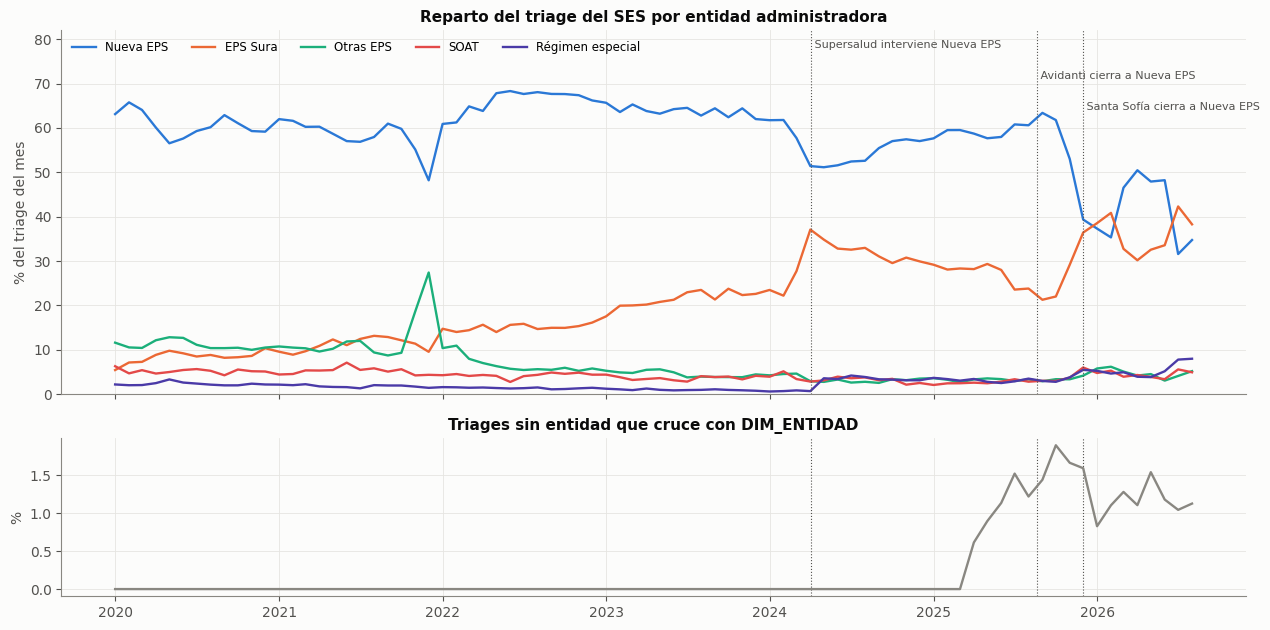

triages en el archivo por entidad hasta 2026-09-21: 433,531; en el diario: 433,392 (diferencia +139)
primer mes con triages sin entidad: 2025-04
el archivo por entidad llega al 2026-09-28; los días posteriores al diario suman 1,195


dia,2021-11,2021-12,2022-01,2024-02,2024-03,2024-04,2025-10,2025-11,2025-12,2026-02,2026-03,2026-06,2026-07,2026-08
grupo,,,,,,,,,,,,,,
nueva_eps,55.2,48.2,60.9,61.8,57.7,51.4,61.8,53.0,39.4,35.3,46.5,48.2,31.6,34.7
sura_eps,11.4,9.6,14.8,22.2,27.7,37.1,22.0,29.2,36.4,40.9,32.8,33.6,42.3,38.3
otra_eps,18.7,27.4,10.4,4.6,4.6,2.9,3.4,3.4,4.2,6.2,5.1,3.1,4.1,5.2
sin_entidad,0.0,0.0,0.0,0.0,0.0,0.0,1.9,1.7,1.6,1.1,1.3,1.2,1.0,1.1


grupo,nueva_eps,sura_eps,otra_eps,soat_aseguradora,regimen_especial,particular,arl,prepagada,sin_entidad
dia,,,,,,,,,
2020,61.3,8.1,11.0,5.3,2.3,2.8,1.5,2.5,0.0
2021,57.6,11.3,13.2,5.2,1.8,3.2,1.3,1.8,0.0
2022,66.1,15.0,6.8,4.3,1.4,1.1,0.9,1.8,0.0
2023,63.9,21.4,4.6,3.7,1.0,0.7,0.9,2.0,0.0
2024,55.4,30.7,3.3,3.4,2.6,0.8,0.9,1.4,0.0
2025,58.0,27.0,3.3,3.0,3.3,0.6,0.8,1.2,1.0
2026,41.7,36.0,4.6,4.5,5.7,0.7,1.3,2.4,1.2


In [12]:
GRUPOS = {"nueva_eps": ("Nueva EPS", AZUL), "sura_eps": ("EPS Sura", NARANJA), "otra_eps": ("Otras EPS", AQUA),
          "soat_aseguradora": ("SOAT", ROJO), "regimen_especial": ("Régimen especial", VIOLETA)}
g = ent.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").fillna(0).loc[:"2026-08-31"]
cuota = 100 * g.resample("MS").sum().pipe(lambda d: d.div(d.sum(axis=1), axis=0))
fig, axes = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
for c, (t, col) in GRUPOS.items():
    axes[0].plot(cuota.index, cuota[c], color=col, lw=1.7, label=t)
for i, (f, t) in enumerate([("2024-04-03", "Supersalud interviene Nueva EPS"), ("2025-08-21", "Avidanti cierra a Nueva EPS"),
                            ("2025-12-01", "Santa Sofía cierra a Nueva EPS")]):
    for ax in axes:
        ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":")
    axes[0].text(pd.Timestamp(f), 78 - 7 * i, " " + t, fontsize=8, color=TINTA2)
axes[0].set_ylabel("% del triage del mes"); axes[0].set_title("Reparto del triage del SES por entidad administradora")
axes[0].legend(loc="upper left", ncol=5, fontsize=8.5); axes[0].set_ylim(0, 82)
axes[1].plot(cuota.index, cuota["sin_entidad"], color=MUDO, lw=1.7)
axes[1].set_ylabel("%"); axes[1].set_title("Triages sin entidad que cruce con DIM_ENTIDAD")
plt.tight_layout(); plt.show()
comun = ent[ent.dia <= tri.dia.max()].n.sum()
print(f"triages en el archivo por entidad hasta {tri.dia.max():%Y-%m-%d}: {comun:,}; en el diario: {tri.triages.sum():,} "
      f"(diferencia {comun - tri.triages.sum():+,})")
print(f"primer mes con triages sin entidad: {cuota.index[cuota.sin_entidad > 0][0]:%Y-%m}")
print(f"el archivo por entidad llega al {ent.dia.max():%Y-%m-%d}; los días posteriores al diario suman {ent[ent.dia > tri.dia.max()].n.sum():,}")
MESES = ["2021-11-01", "2021-12-01", "2022-01-01", "2024-02-01", "2024-03-01", "2024-04-01", "2025-10-01", "2025-11-01",
         "2025-12-01", "2026-02-01", "2026-03-01", "2026-06-01", "2026-07-01", "2026-08-01"]
display(cuota.loc[MESES, ["nueva_eps", "sura_eps", "otra_eps", "sin_entidad"]].round(1).rename(index=lambda d: f"{d:%Y-%m}").T)
ga = ent.groupby([ent.dia.dt.year, "grupo"]).n.sum().unstack(fill_value=0)
(100 * ga.div(ga.sum(axis=1), axis=0)).round(1)[["nueva_eps", "sura_eps", "otra_eps", "soat_aseguradora", "regimen_especial",
                                                  "particular", "arl", "prepagada", "sin_entidad"]]

## Lectura

**El reparto entre aseguradores cambia por escalones, no de forma gradual.**

| Mes | 2021-11 | 2021-12 | 2024-02 | 2024-04 | 2025-10 | 2025-12 | 2026-03 | 2026-06 | 2026-07 |
|---|---|---|---|---|---|---|---|---|---|
| Nueva EPS % | 55,2 | 48,2 | 61,8 | 51,4 | 61,8 | **39,4** | 46,5 | 48,2 | **31,6** |
| EPS Sura % | 11,4 | 9,6 | 22,2 | **37,1** | 22,0 | 36,4 | 32,8 | 33,6 | 42,3 |
| Otras EPS % | 18,7 | **27,4** | 4,6 | 2,9 | 3,4 | 4,2 | 5,1 | 3,1 | 4,1 |

- **Diciembre de 2021:** «otras EPS» sube al 27 %. Coincide con la liquidación de Medimás, según el 07.
- **Entre febrero y abril de 2024** Sura pasa del 22 al 37 %. En abril la Supersalud interviene Nueva EPS.
- **Noviembre y diciembre de 2025:** Nueva EPS cae del 62 al 39 %. Se recupera en parte en marzo de
  2026 y vuelve a caer en julio de 2026 (32 %).
- Por año, Nueva EPS pasa del 61,3 % (2020) al 41,7 % (2026) y Sura del 8,1 % al 36,0 %. Régimen
  especial sube del 2,6 % (2024) al 5,7 % (2026).

**Un escalón de calidad: desde 2025 aparecen triages sin entidad.** Eran 0 hasta 2024. Son el
1,0 % en 2025 y el 1,2 % en 2026, y el primer mes con ellos es abril de 2025. Es poco, pero es un cambio de
registro.

**Coherencia con el diario.** Hasta el 2026-09-21, el archivo por entidad suma 433.531 triages y el
diario 433.392: 139 más. El archivo por entidad llega además al 2026-09-28.

**Límite.** La cuota dice cómo se reparte la demanda, no por qué. Las fechas de suspensión y
reanudación entre el SES y Nueva EPS no existen como dato (sección 8).

---
# 6. Calendario, eventos y desastres

## 6.1 El calendario de Colombia

**Qué es.** Una fila por día con festivos, puentes, quincena, vacaciones escolares, Semana Santa y
temporadas. Es el **control** del proyecto, no el producto.
- Los festivos salen de la librería `holidays`, con los festivos de ley trasladados al lunes.
- Semana Santa sale de la fecha de Pascua.
- **Las vacaciones escolares y el regreso a clases son reglas fijas del script**, no el calendario
  oficial de la Secretaría de Educación.
- Se conoce de antemano, así que puede entrar al pronóstico sin rezago.

In [13]:
fest = calc.groupby(calc.index.year)[["es_festivo", "es_puente", "es_semana_santa", "es_vacaciones_escolares", "es_regreso_colegio"]].sum()
fest["vacaciones y regreso a la vez"] = ((calc.es_vacaciones_escolares == 1) & (calc.es_regreso_colegio == 1)).groupby(calc.index.year).sum()
fs = calc[calc.es_festivo == 1].nombre_festivo.str.replace(r" \(observado\)", "", regex=True)
por_anio = fs.groupby(fs.index.year).apply(lambda x: set(n for t in x for n in t.split("; ")))
print("2025-06-30:", calc.loc["2025-06-30", "nombre_festivo"])
print("festivos de 2026 que no aparecen en 2020-2025:", sorted(por_anio[2026] - set().union(*por_anio.loc[2020:2025])))
fest

2025-06-30: Sagrado Corazón (observado); San Pedro y San Pablo (observado)
festivos de 2026 que no aparecen en 2020-2025: ['Día de Nuestra Señora del Rosario de Chiquinquirá']


,es_festivo,es_puente,es_semana_santa,es_vacaciones_escolares,es_regreso_colegio,vacaciones y regreso a la vez
fecha,,,,,,
2020,18,11,8,122,53,53
2021,18,10,8,122,53,53
2022,18,10,8,122,53,53
2023,18,13,8,122,53,53
2024,18,11,8,122,53,53
2025,17,10,8,122,53,53
2026,19,12,8,122,53,53


## Lectura

- **17 días festivos en 2025 y 19 en 2026, contra 18 los demás años.**
  - En 2025, el Sagrado Corazón y San Pedro y San Pablo caen el mismo lunes, el 30 de junio.
  - En 2026, la librería añade el 13 de julio, «Día de Nuestra Señora del Rosario de Chiquinquirá».
    **No se verificó aquí contra la norma que lo crea.**
- **Las vacaciones escolares son las mismas 122 fechas todos los años**: enero, junio, julio, desde
  el 10 de diciembre y Semana Santa. Es una aproximación, no el calendario de cada año.
- **Defecto: los 53 días de «regreso a clases» caen todos dentro de «vacaciones escolares».** El
  script marca como regreso del 10 al 31 de enero y todo julio, que también son vacaciones. En el
  control de calendario las dos variables se pisan.
- Existen las resoluciones oficiales de la Secretaría de Educación de Manizales en PDF (2025 y 2026,
  `FUENTES_EXTERNAS.md`, 4.4). Son unas 6 fechas por año, a mano.

## 6.2 Los tres calendarios manuales: eventos, desastres y vigilancia

Son listas escritas a mano, cada fila con su `fuente_url`. Están **por reemplazar** por series de
fuentes oficiales; no se borran porque son el registro de lo que había. La tabla final cuenta de qué
dominio sale cada fila.

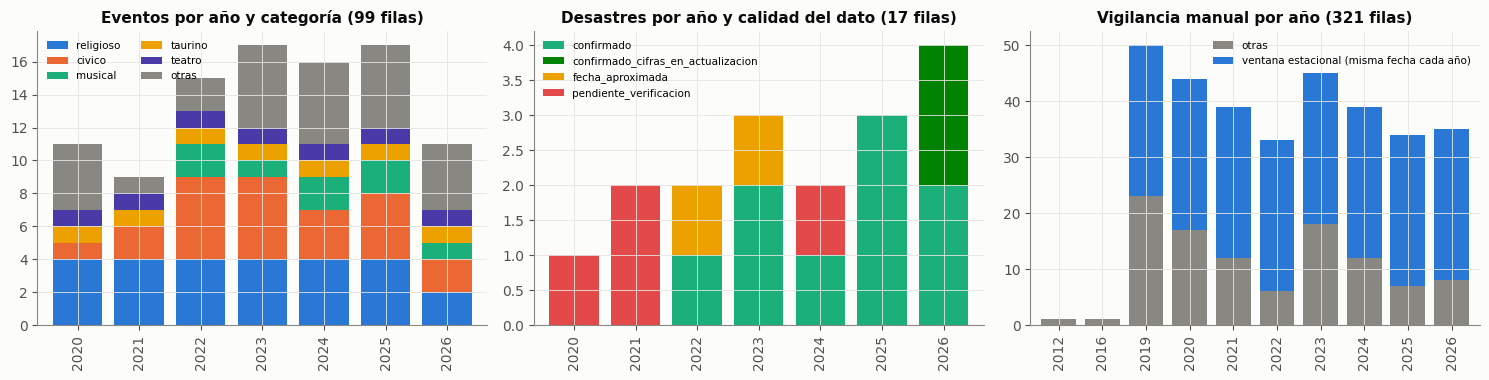

ventana_estacional: 216 de 321 (67%); con número de casos: 28
desastres por calidad: {'confirmado': 9, 'pendiente_verificacion': 4, 'fecha_aproximada': 2, 'confirmado_cifras_en_actualizacion': 2}


,eventos,desastres,vigilancia manual,total
fuente_url,,,,
(sin URL),0,0,117,117
ins.gov.co,0,0,80,80
ideam.gov.co,0,0,49,49
eltiempo.com,18,0,5,23
arquidiocesisdemanizales.com,23,0,0,23
minsalud.gov.co,1,0,14,15
infobae.com,4,2,5,11
centrodeinformacion.manizales.gov.co,3,4,4,11
paho.org,0,0,8,8


In [14]:
dom = lambda s: s.fillna("").map(lambda u: urlparse(u).netloc.replace("www.", "") or "(sin URL)")
ev_anio = eventos.assign(anio=pd.to_datetime(eventos.fecha_inicio).dt.year).dropna(subset=["anio"]).astype({"anio": int})
top_cat = ev_anio.categoria.value_counts().index[:5]
ev_anio["cat"] = ev_anio.categoria.where(ev_anio.categoria.isin(top_cat), "otras")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
t1 = ev_anio.pivot_table(index="anio", columns="cat", values="nombre_evento", aggfunc="count").fillna(0)
t1[list(top_cat) + ["otras"]].plot.bar(stacked=True, ax=axes[0], color=[AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, MUDO], width=.8)
axes[0].set_title("Eventos por año y categoría (99 filas)"); axes[0].legend(fontsize=7.5, ncol=2); axes[0].set_xlabel("")
d_anio = desastres.assign(anio=pd.to_datetime(desastres.fecha_inicio).dt.year)
t2 = d_anio.pivot_table(index="anio", columns="calidad_dato", values="tipo_evento", aggfunc="count").fillna(0)
t2.plot.bar(stacked=True, ax=axes[1], color=[AQUA, VERDE, AMARILLO, ROJO][:t2.shape[1]], width=.8)
axes[1].set_title("Desastres por año y calidad del dato (17 filas)"); axes[1].legend(fontsize=7.5); axes[1].set_xlabel("")
v_anio = vman.assign(anio=pd.to_datetime(vman.fecha_inicio).dt.year,
                     tipo=np.where(vman.estado.eq("ventana_estacional"), "ventana estacional (misma fecha cada año)", "otras"))
t3 = v_anio.pivot_table(index="anio", columns="tipo", values="nombre_evento", aggfunc="count").fillna(0)
t3.plot.bar(stacked=True, ax=axes[2], color=[MUDO, AZUL], width=.8)
axes[2].set_title("Vigilancia manual por año (321 filas)"); axes[2].legend(fontsize=7.5); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()
fu = pd.concat({"eventos": dom(eventos.fuente_url).value_counts(), "desastres": dom(desastres.fuente_url).value_counts(),
                "vigilancia manual": dom(vman.fuente_url).value_counts()}, axis=1).fillna(0).astype(int)
fu["total"] = fu.sum(axis=1)
print("ventana_estacional:", int((vman.estado == "ventana_estacional").sum()), "de", len(vman),
      f"({(vman.estado == 'ventana_estacional').mean():.0%}); con número de casos: {int(vman.casos.notna().sum())}")
print("desastres por calidad:", desastres.calidad_dato.value_counts().to_dict())
fu.sort_values("total", ascending=False).head(12)

## Lectura

- **Eventos (99 filas):** 9 a 17 por año, casi todos recurrentes anuales. Las fuentes más citadas son
  la Arquidiócesis (23) y El Tiempo (18). **Tiene fechas, no
  intensidad**: no dice cuánta gente fue.
- **Desastres (17 filas):** 4 pendientes de verificación y 2 con fecha aproximada. Los sustituirá la
  UNGRD, que según `FUENTES_EXTERNAS.md` registra 80 emergencias en Manizales entre 2019 y 2025.
- **Vigilancia manual (321 filas):** 216 (67 %) son ventanas estacionales, las mismas fechas cada año.
  Solo 28 traen número de casos, y 117 no tienen URL. **Es calendario disfrazado**; ya la sustituyen
  el SIVIGILA y el Power BI.

**Qué pueden sostener.** Marcar fechas conocidas, como la Feria o el terremoto.

**Qué no.** Medir intensidad, ni servir de variable de salud: sus ventanas las explica el mes del
año (cuaderno 05).

---
# 7. Calidad: escalones y caídas de registro conocidos

Cada fila está medida en este cuaderno o en el documento citado. «Nuevo» quiere decir que apareció
al graficar las fuentes aquí.

| Fuente | Qué pasa | Fecha | Magnitud | Cómo se trata |
|---|---|---|---|---|
| Triage | Días sin filas y caída parcial | 2024-03-19 y 20; el 21 con 40 triages | caída del registro | nulo en el total; excluido por la regla del 40 % (cuadernos 06 y 07) |
| 995 | Calidad baja | 2012-2014 | duplicados, semanas con 2 instituciones | la serie empieza en 2015 |
| 995 | El denominador crece por escalones | 2020→2021, 2023→2024 | +60 %, +35 % | proporción solo dentro del año; conteo entre años; panel fijo pendiente |
| 995 | El SES está en el denominador | 2015-2025 | 6-10 % | se excluye de «consultas de la ciudad» |
| 998 | Caída de la EDA y de las instituciones que notifican | desde 2020 | índice 100 → 42-43; instituciones 33,6 → ~21 | sin resolver |
| Eventos SIVIGILA | 831, 414 (y 365), 549, 113, 348, 155 | 2015-2023 | −92 %, −93 %, ×3, ×2,9, COVID, año sin publicar | mirar la serie; usar solo dentro de un régimen |
| Eventos SIVIGILA | La fecha que define la semana cambia | por evento y año | desplaza casos entre semanas | `casos_ocurrencia_semana_consulta` para el histórico |
| Power BI 995 | Nivel por encima de los microdatos | todos los años | IRA +3,4 a +7,9 % | factor por año, o proporción |
| Power BI 995 | **Semana rota (nuevo)** | SE52 de 2021 | 96 contra 814 | excluirla al empalmar |
| Power BI 995 | Sin 2020 | 2020 | — | microdatos para 2020 |
| Power BI 300 | Total por debajo | 2024 | −8,3 % | sin explicar |
| Clima | **Pluviómetro en cero, marcado como dato bueno (nuevo)** | 2025-10, 2026-01 a 2026-06 → *(29-09)* 199 días, 2025-10-05 a 2026-07-08 | 0 mm contra 99-237 de NASA | ~~pendiente~~ → **corregido el 2026-09-29**: `pluviometro_fallido` los trata como sin pluviómetro; queda repetir lo que use lluvia |
| Clima | **Nivel de toda la lluvia (nuevo, 29-09)** | 2020-2026 | +15 a +25 % por año al quitar la falla | efecto del factor de escala de NASA; no comparar niveles de antes y después del 29-09 |
| Clima | **2021 sin ninguna medida en tierra (nuevo)** | 2021 | 0 días de pluviómetro; 57 de METAR | tratar 2021 como reanálisis |
| Clima | Sin pluviómetro | 2020-08 a 2021-12; 2023-04 a 2024-06; *(29-09)* y los 199 días en falla | — | NASA escalado; acumulados de 7 días |
| Clima | Mes al borde del umbral de falla (nuevo, 29-09) | 2025-08 | 13 mm contra 119 de NASA, razón 0,111 | queda como dato; no se sabe si es falla |
| Clima | Planalto y lluvia ERA5 | 2020-2023 | +7,4 °C; 16.555 mm/año | ya excluidos (`CLIMA.md`) |
| MinDefensa | **Pozo de registro en tránsito (precisado)** | 2018-2019 | 279 casos y 38 % de días con caso en 2019 | usar 2021 en adelante |
| MinDefensa | Lesiones personales | 2018→2025 | −62 % | no leerlo como realidad |
| MinDefensa | Violencia intrafamiliar | 2019; 2025 | 395 → 688; 760 → 475 | mirar la serie |
| Entidad | **Triages sin entidad (nuevo)** | desde 2025-04 | 1,0-1,2 % | grupo aparte |
| Entidad | Escalones del reparto | 2021-12, 2024-04, 2025-11, 2026-07 | 9-22 puntos de cuota | son la red, no un error: variable explícita |
| Calendario | **Regreso a clases dentro de vacaciones (nuevo)** | todos los años | 53 de 53 días | corregir con las resoluciones oficiales |
| Calendario | Festivo del 13-jul-2026 | 2026 | 19 festivos | verificar contra la norma |
| Manuales | Fechas fijas y filas sin verificar | 2012-2026 | 67 % ventanas; 4 desastres pendientes | reemplazar por fuentes oficiales |

> **Corrección del 2026-09-29 (clima corregido).** En esta tabla, la fila del pluviómetro en cero pasa
> de **«pendiente»** a **corregida** (fechas: siete meses → 199 días del 2025-10-05 al 2026-07-08), y la
> fila «Sin pluviómetro» suma esos días. Se añaden dos filas: el **salto de nivel del 15-25 %** de toda
> la lluvia, que es consecuencia de la corrección, y **agosto de 2025**, que queda al borde del umbral.
> Lo tachado se deja a la vista.

---
# 8. Lo que no existe como dato

Tres cosas que harían falta y que ningún archivo tiene. Las dos primeras dependen de acciones del
propietario (decisiones #10 y #11 de `docs/HANDOFF.md`).

**1. Alertas hospitalarias (verde, amarilla, naranja, roja).**
- No hay registro estructurado, solo comunicados sueltos de:
  - la Dirección Territorial de Salud de Caldas (`saluddecaldas.gov.co`);
  - la Gobernación (`caldas.gov.co`);
  - la Alcaldía (`centrodeinformacion.manizales.gov.co`, que tiene API de noticias).
- **Se pidió al propietario** (#10c) un derecho de petición a la DTSC con:
  - los actos de declaratoria y levantamiento de alertas de 2020-2026;
  - las novedades REPS de cierre o reducción de urgencias, hospitalización y UCI;
  - la ocupación.
- Mientras llega, se puede armar a mano desde las noticias de la Alcaldía.

**2. Las fechas de la relación SES-Nueva EPS.**
- La sección 5 muestra los escalones de noviembre de 2025, marzo de 2026 y julio de 2026. Pero
  **no hay fechas** de suspensión, reanudación o cambio de contrato.
- **Se pidieron al propietario** (#11). Con ellas, la variable de mayor efecto pasa a ser un
  predictor conocido **por adelantado**.
- En la misma línea (#10d, e, g) están pendientes:
  - el histórico de afiliados por EPS de MinSalud;
  - el histórico de medidas de la Supersalud;
  - guardar cada mes la foto de la BDUA, que no guarda historia.

**3. El calendario de fiestas de los municipios cercanos.** Es una hipótesis del propietario para
los picos de enero: lo que el hospital del pueblo no atiende termina en Manizales. **Lo está
construyendo otro agente ahora mismo** y no se incluye aquí.

**Y uno que existe pero no está integrado:** el **pronóstico** del clima archivado (Open-Meteo,
temperatura desde 2021-03 y lluvia desde 2024-01, `FUENTES_EXTERNAS.md` 5.1). Sin él, cualquier
evaluación con clima observado mide algo que en operación no se tendrá.